# HW09 - Native Cadence GUI result review

Select **ECE6420 (Local)**. This notebook receives existing native Virtuoso/ADE results, validates actual GUI-exported images and prepares editable LaTeX source locally. **Run All does not launch Spectre or press ADE Run.** Run changed schematic experiments from the native ADE GUI first. The earlier Python-generated-netlist experiment remains in `00_overview.ipynb` as a separate baseline.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys

_candidates = [Path.cwd().resolve(), Path.cwd().resolve() / 'HW09', *Path.cwd().resolve().parents]
ROOT = next((p for p in _candidates if (p / 'lib/cadence_review_bridge.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the HW09 project.')
sys.path.insert(0, str(ROOT / 'lib'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'simulation/matplotlib'))
from cadence_review_bridge import preserve_python_baseline, fetch_gui_artifacts, import_actual_gui_results, render_gui_figures, render_gui_tex
print('Local interpreter:', sys.executable)
print('Kernel: ECE6420 (Local)')
print('Native experiments run from ADE; this notebook only fetches and reviews their data.')
%matplotlib inline

Local interpreter: /Users/jeonsang-eon/Gatech-ECE6420/HW09/.venv/bin/python
Kernel: ECE6420 (Local)
Native experiments run from ADE; this notebook only fetches and reviews their data.


In [2]:
FETCH_FROM_SERVER = True
MANIFEST_RELATIVE = 'cadence/gui_run_manifest.json'
BUILD_TEX = True
ALLOW_PARTIAL_REVIEW = False
# Set FETCH_FROM_SERVER=False to review the existing local native data without VPN.
# MANIFEST_RELATIVE must identify the operator's actual-run record, not a planning file.

## Actual experiment record

The operator creates the manifest only after observing **ADE Run**, using the actual native history, generated netlist, log, and PSF paths. This notebook does not invent GUI launch timestamps or turn a planning file into run evidence. Fetching preserves the local manifest, copies the editable OA/state backup with `*.cdslck*` excluded, and never deletes files or pushes source to the server.

In [4]:
BASELINE = preserve_python_baseline(ROOT)
print('Immutable Python baseline:', BASELINE)
if FETCH_FROM_SERVER:
    FETCH_RECORD = fetch_gui_artifacts(ROOT)
    print(FETCH_RECORD)
else:
    print('Offline review: native source and GUI data are read from the local HW09 tree.')

Immutable Python baseline: {'path': '/Users/jeonsang-eon/Gatech-ECE6420/HW09/results/python_baseline.json', 'sha256': 'fe527e03cad03f230ff52c43c945f7d10d4d48b49cf14bc2fc2e6675aa9ca8f6', 'run_id': 'ab6a7104f23d'}
Offline review: native source and GUI data are read from the local HW09 tree.


In [5]:
GUI_RESULTS = import_actual_gui_results(ROOT, MANIFEST_RELATIVE)
print('Actual GUI campaign:', GUI_RESULTS['run_id'])
print('Status:', GUI_RESULTS['status'])
if GUI_RESULTS['status'] != 'complete' and not ALLOW_PARTIAL_REVIEW:
    raise RuntimeError('Complete the missing native ADE measurements before final review/reporting.')
for kind, row in GUI_RESULTS['circuits'].items():
    print(kind, json.dumps(row.get('metrics', {}), indent=2))

{"status": "complete", "run_id": "cadence_gui_ab6a7104f23d"}
Actual GUI campaign: cadence_gui_ab6a7104f23d
Status: complete
active {
  "voltage_gain_db": 8.573326509988187,
  "rf_node_gain_db": 8.625449756948662,
  "power_gain_db": 1.5836264666279996,
  "conversion_loss_db": -8.573326509988187,
  "power_conversion_loss_db": -1.5836264666279996,
  "power_mw": 0.685075201414662,
  "p1db_dbm": -15.546875,
  "iip3_dbm": -2.7177206658717927,
  "iip3_lower_dbm": -2.7133931442740304,
  "iip3_upper_dbm": -2.7177206658717927,
  "ssb_nf_db": 11.146078010718469,
  "dsb_nf_db": 8.123825167025998
}
passive {
  "voltage_gain_db": -5.975240900928761,
  "rf_node_gain_db": -5.0843327543236505,
  "power_gain_db": -12.964940944288948,
  "conversion_loss_db": 5.975240900928761,
  "power_conversion_loss_db": 12.964940944288948,
  "power_mw": 0.0,
  "p1db_dbm": -15.078125,
  "iip3_dbm": -5.4724276271271854,
  "iip3_lower_dbm": -5.470790428264643,
  "iip3_upper_dbm": -5.4724276271271854,
  "ssb_nf_db": 16.69

## Verified actual native GUI images

When `plot_figure_mode=cadence_gui_export`, this cell verifies and displays the twelve already exported native ViVA images and their exact numerical-source records. It does not regenerate them with Matplotlib or substitute missing images. Capture/export new plots in Cadence first. Earlier local Python renderings remain only as archive/baseline material; the report's numerical tables retain independently audited measurements.

active_compression: actual native GUI export


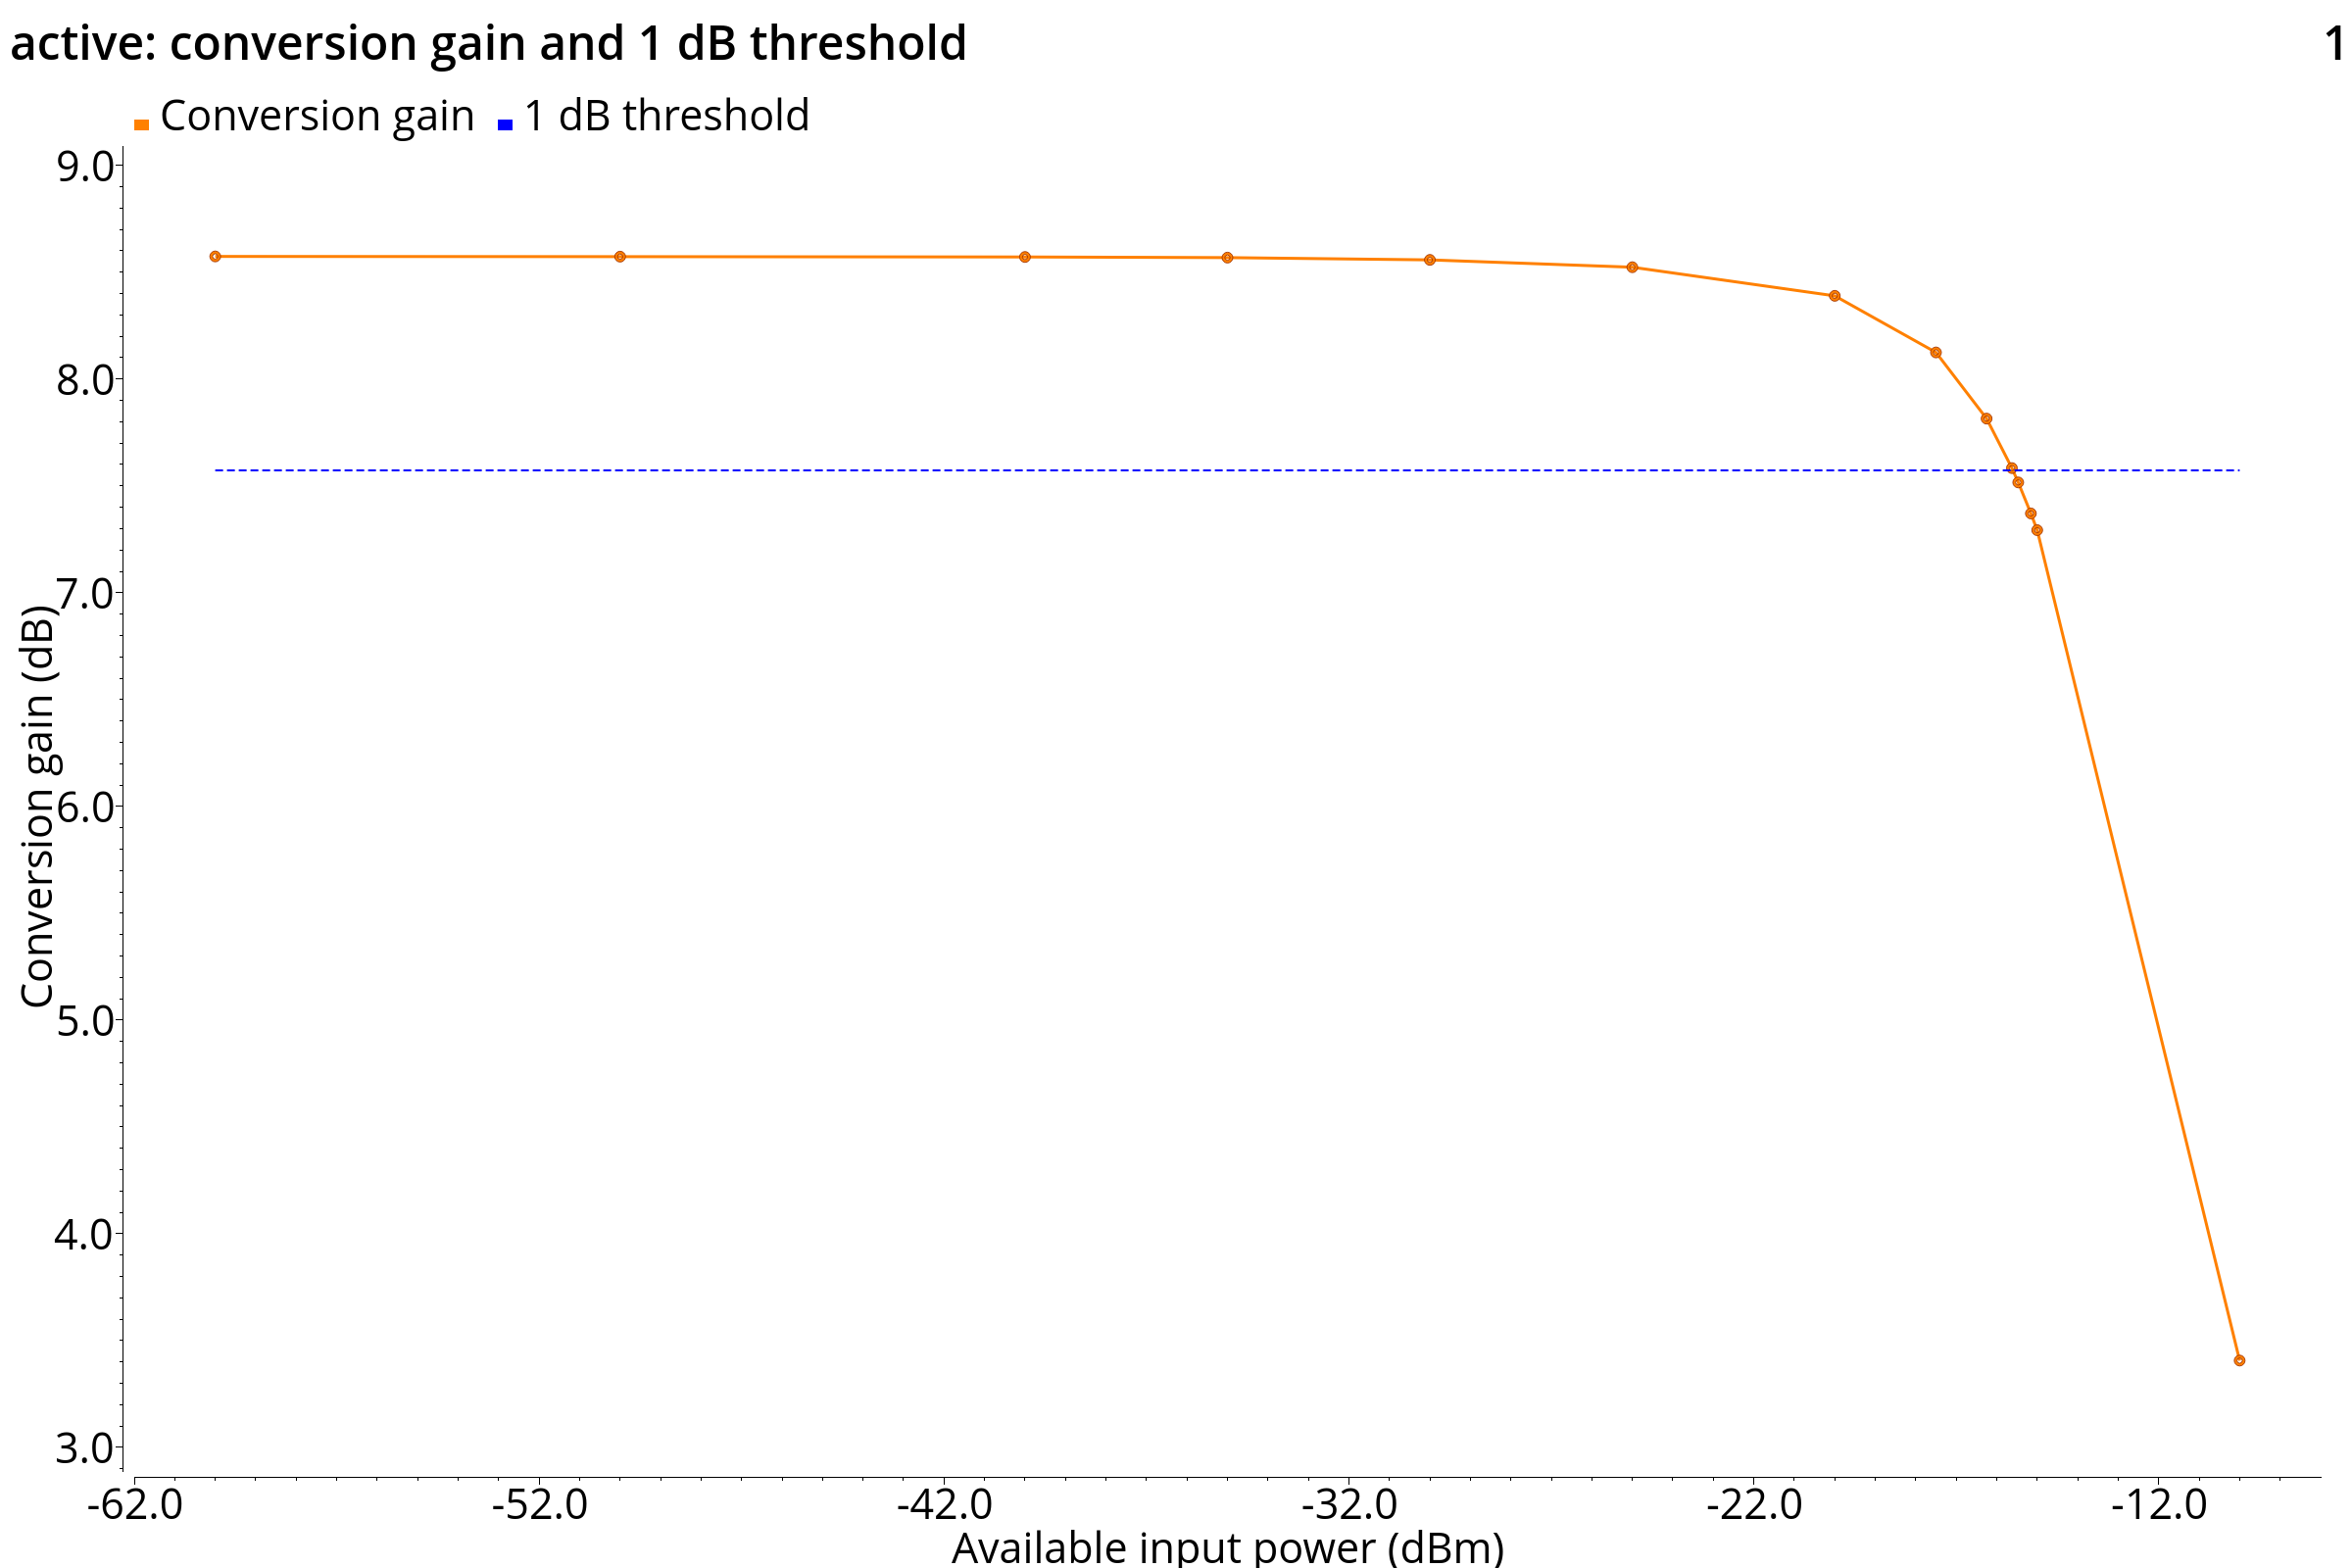

active_iip3: actual native GUI export


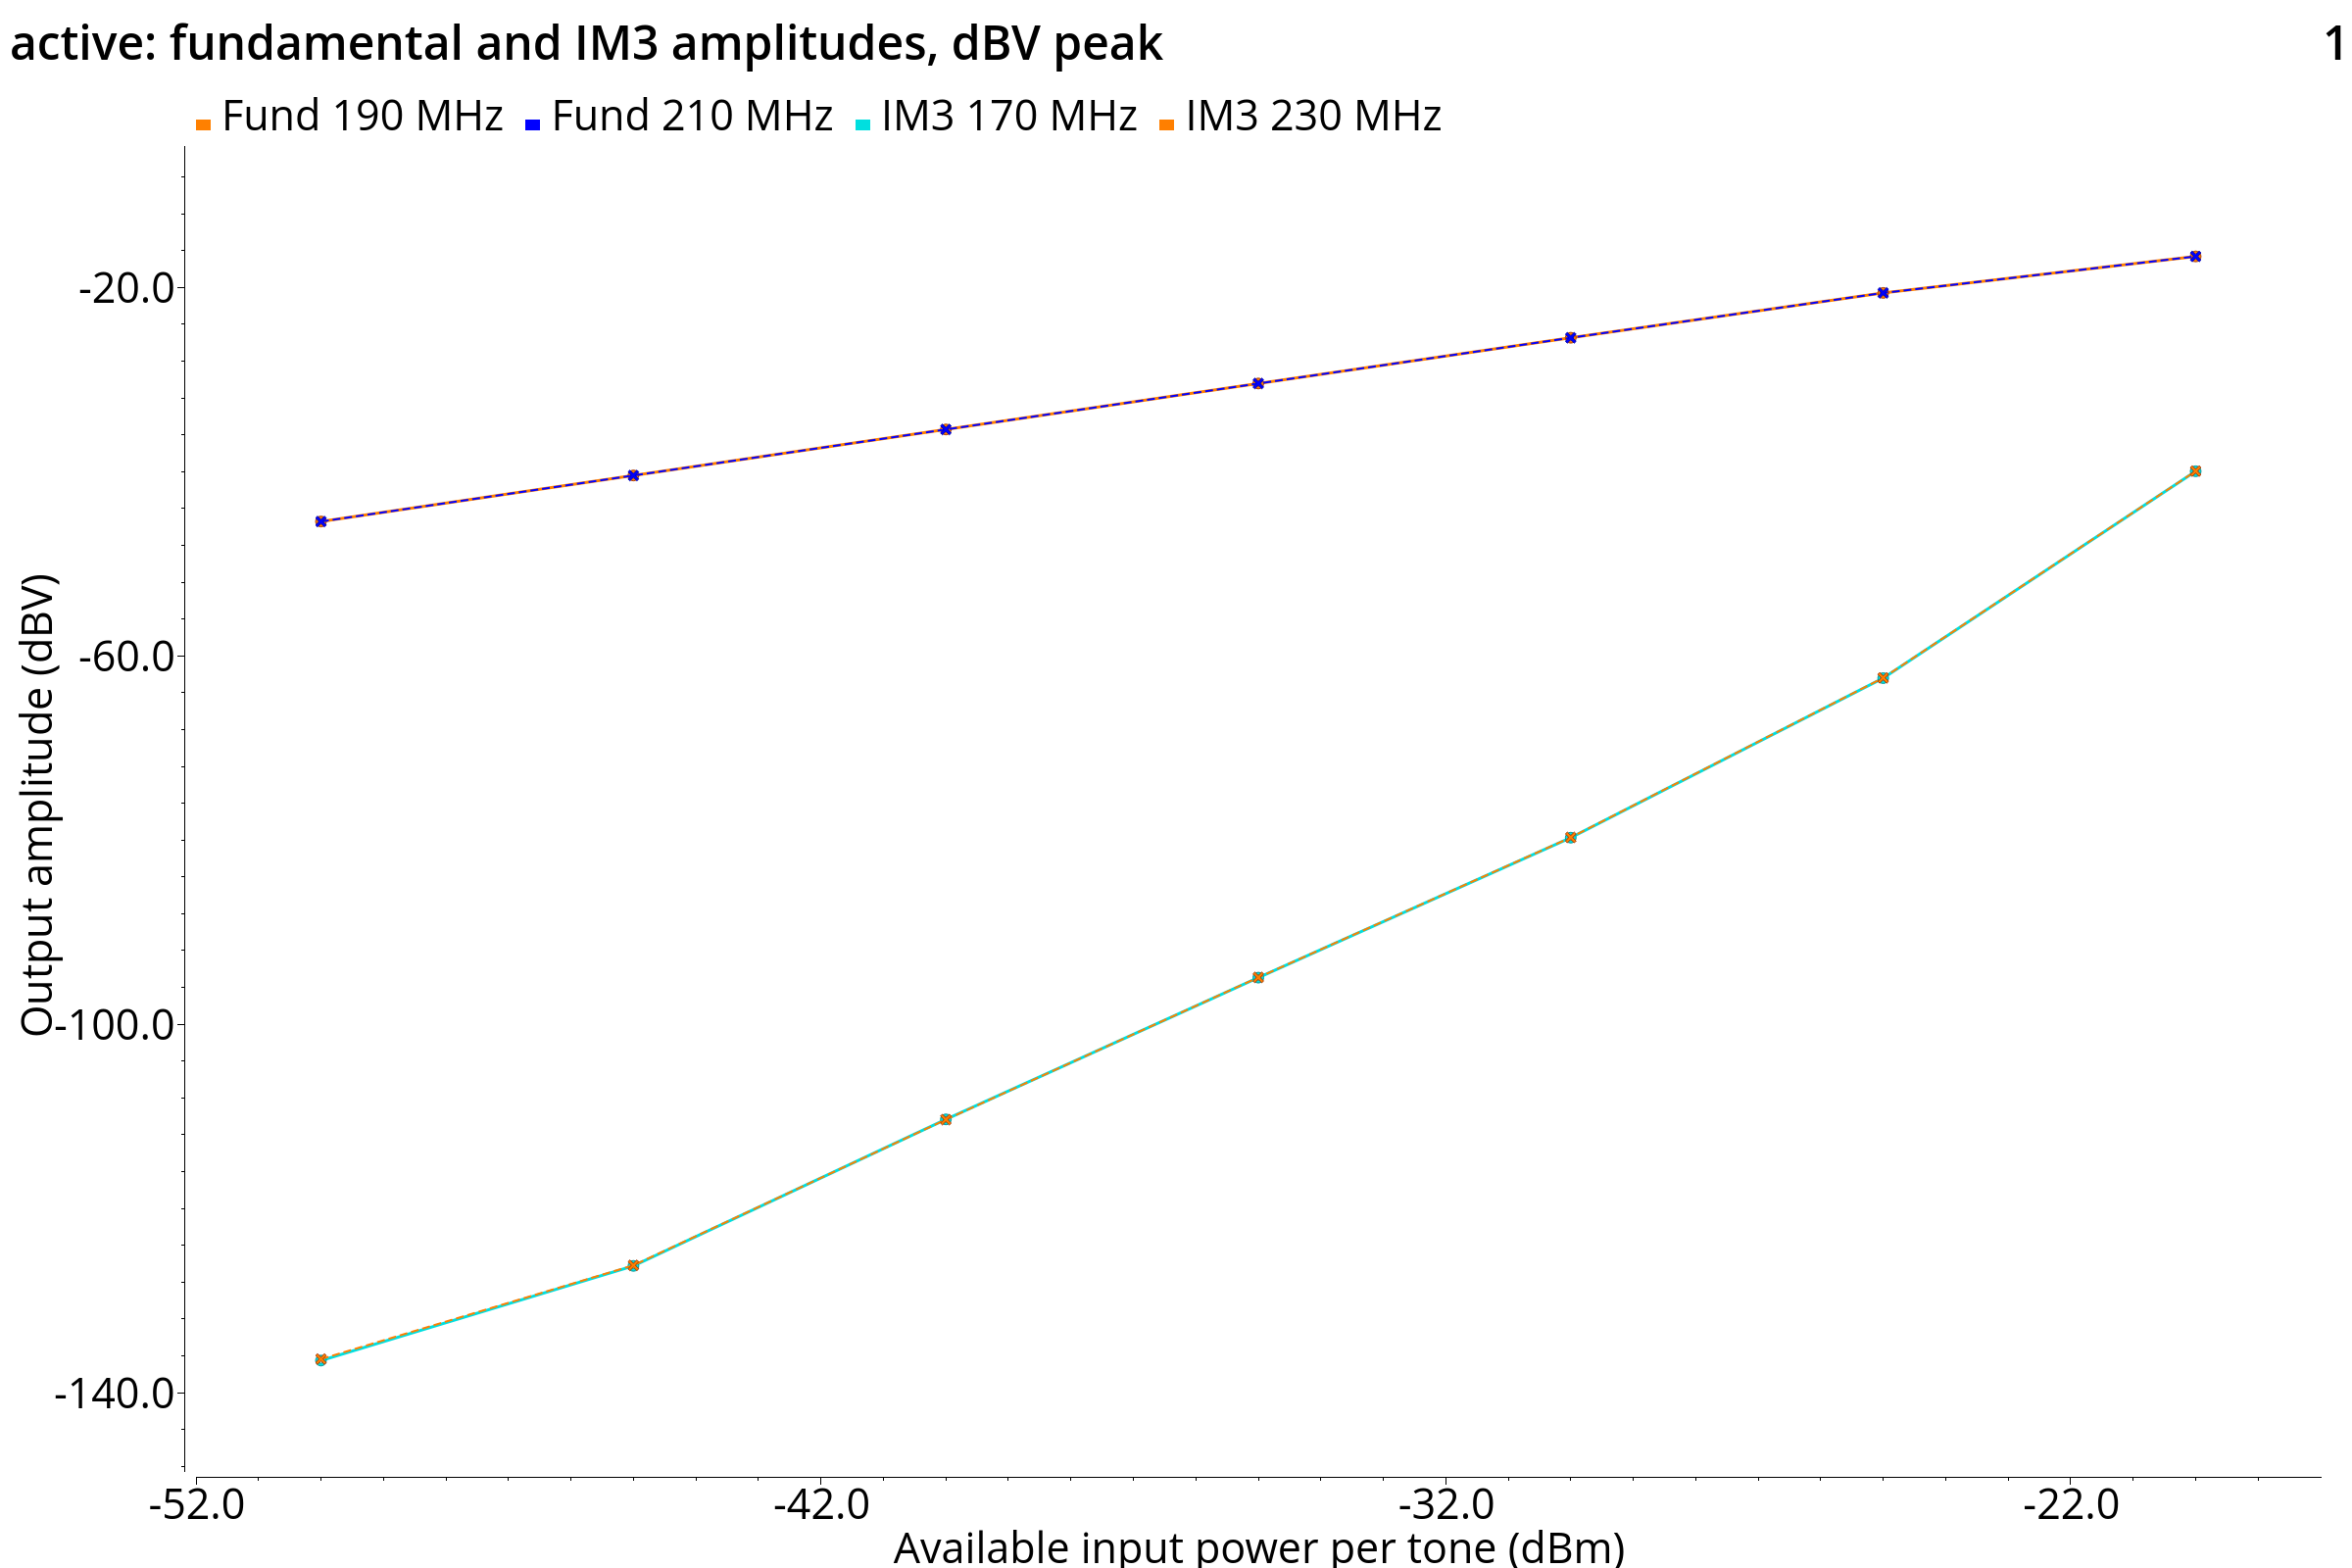

active_noise: actual native GUI export


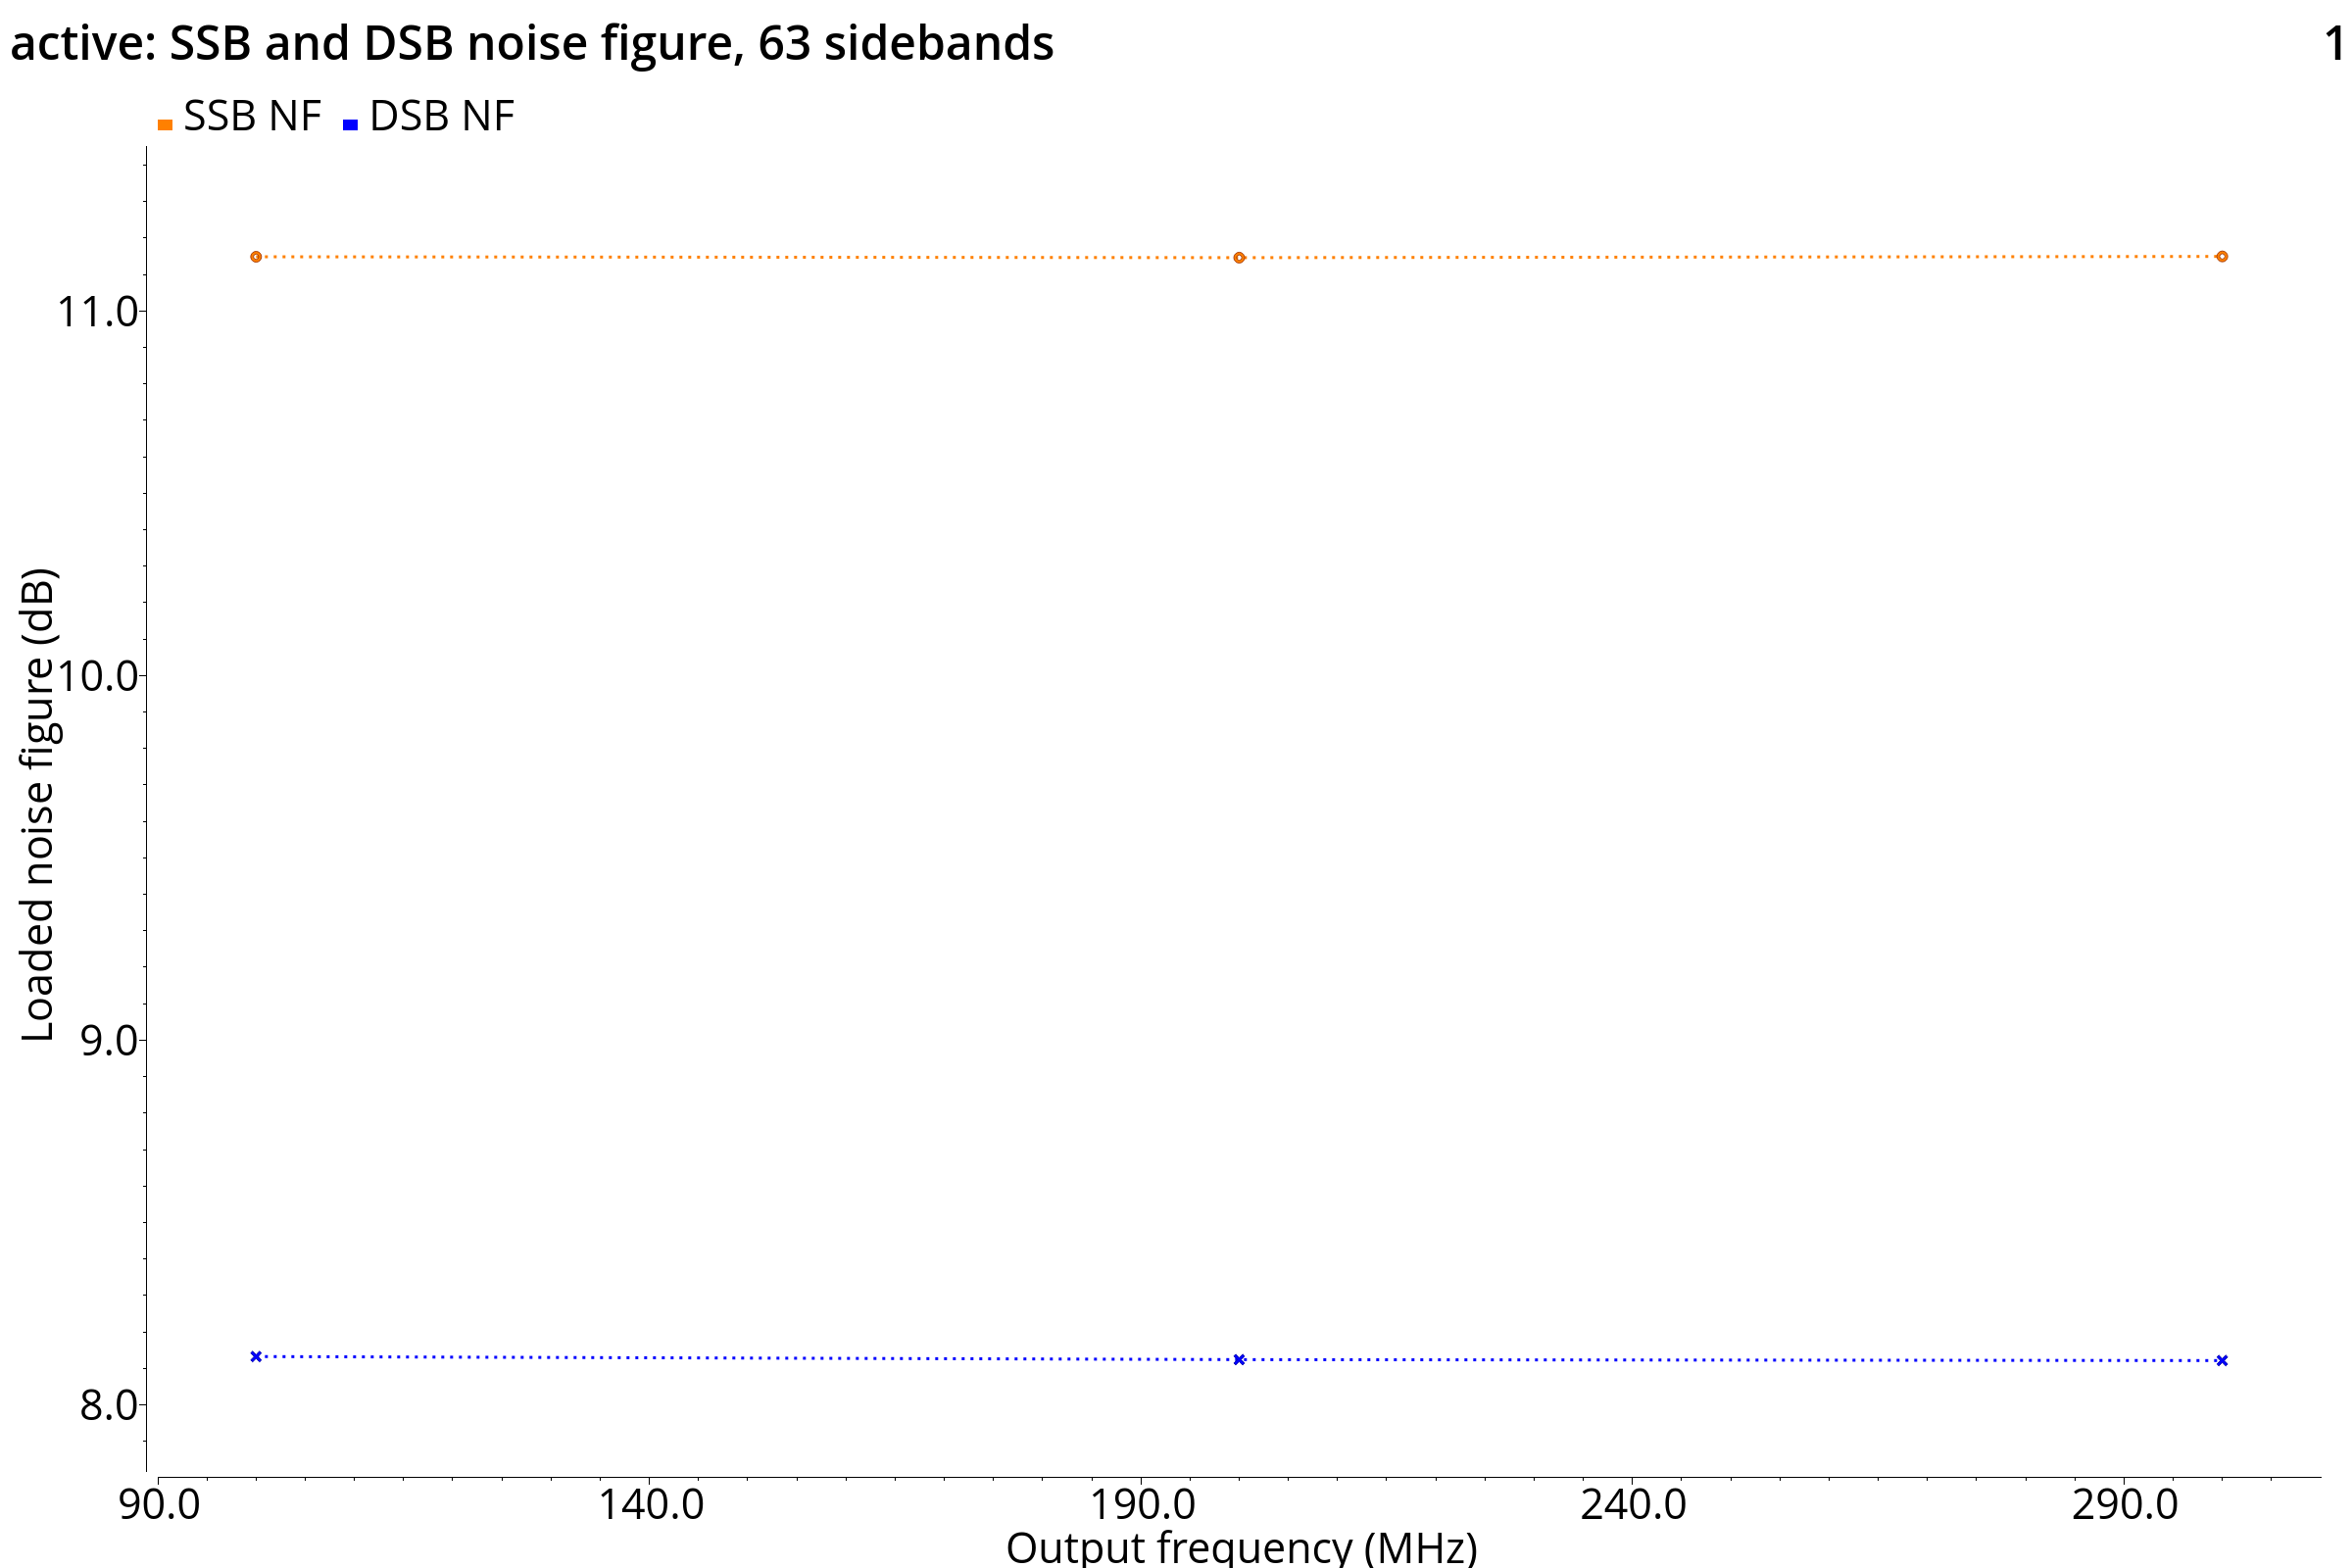

active_spectrum: actual native GUI export


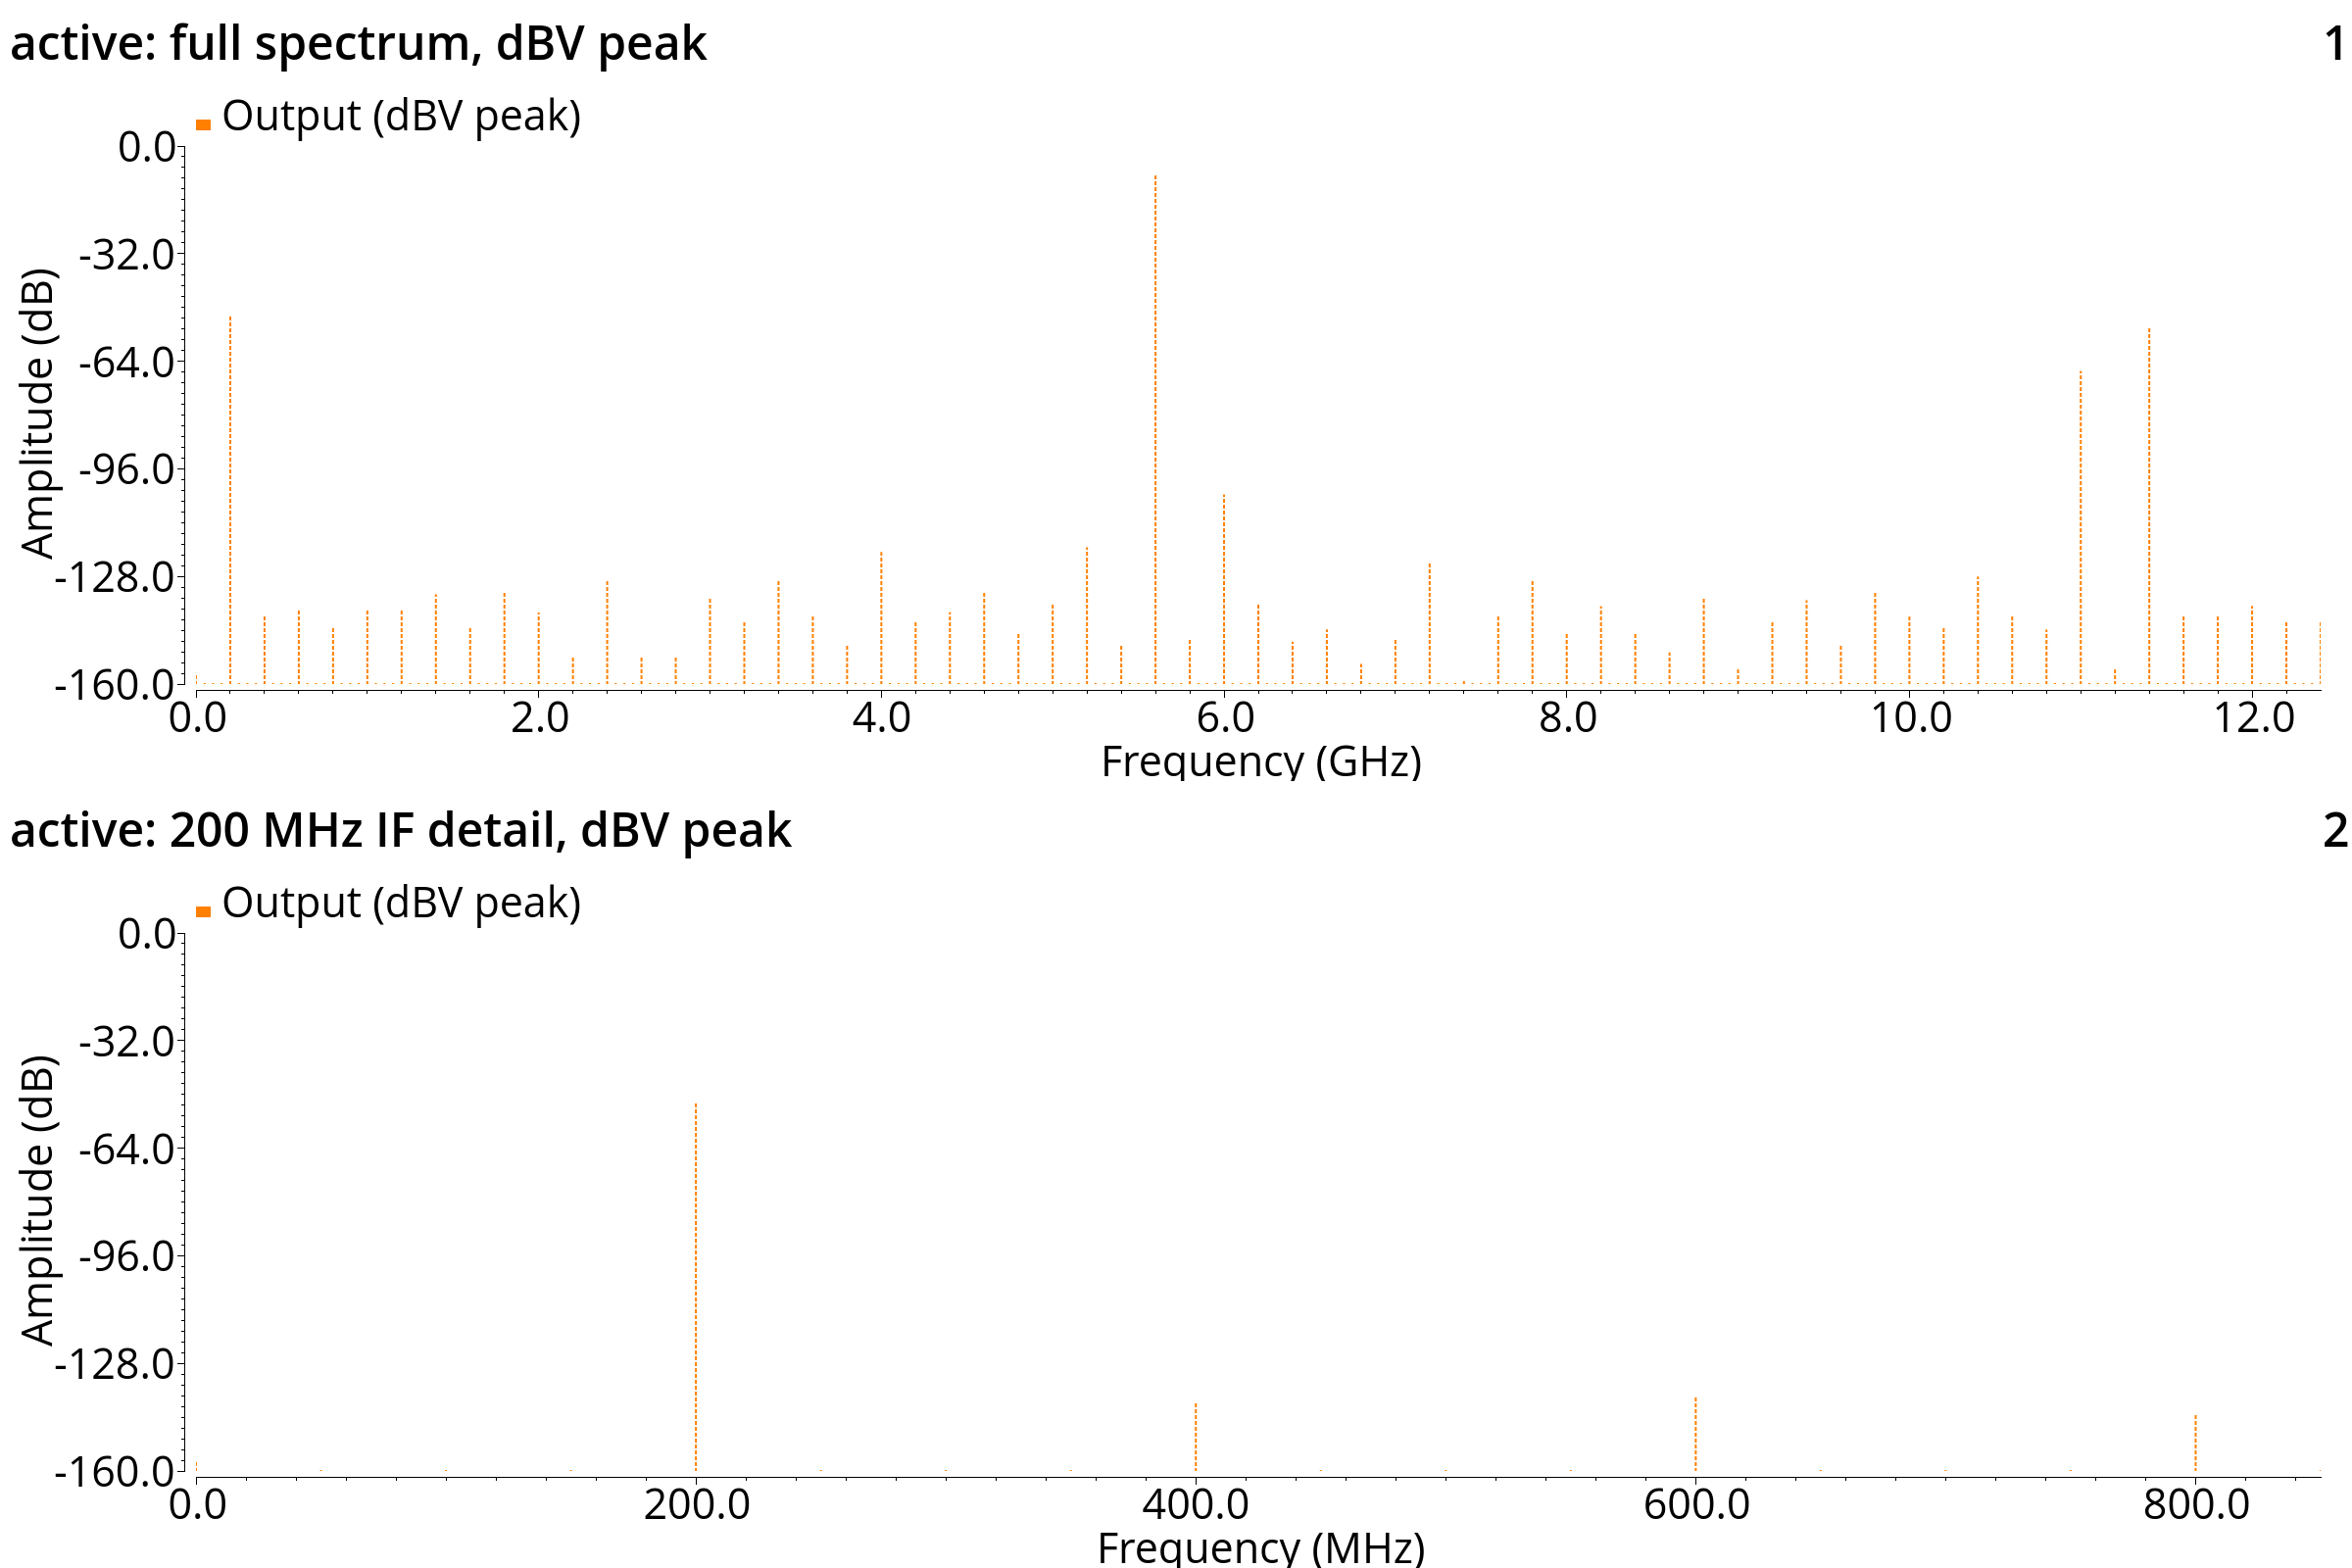

active_transient: actual native GUI export


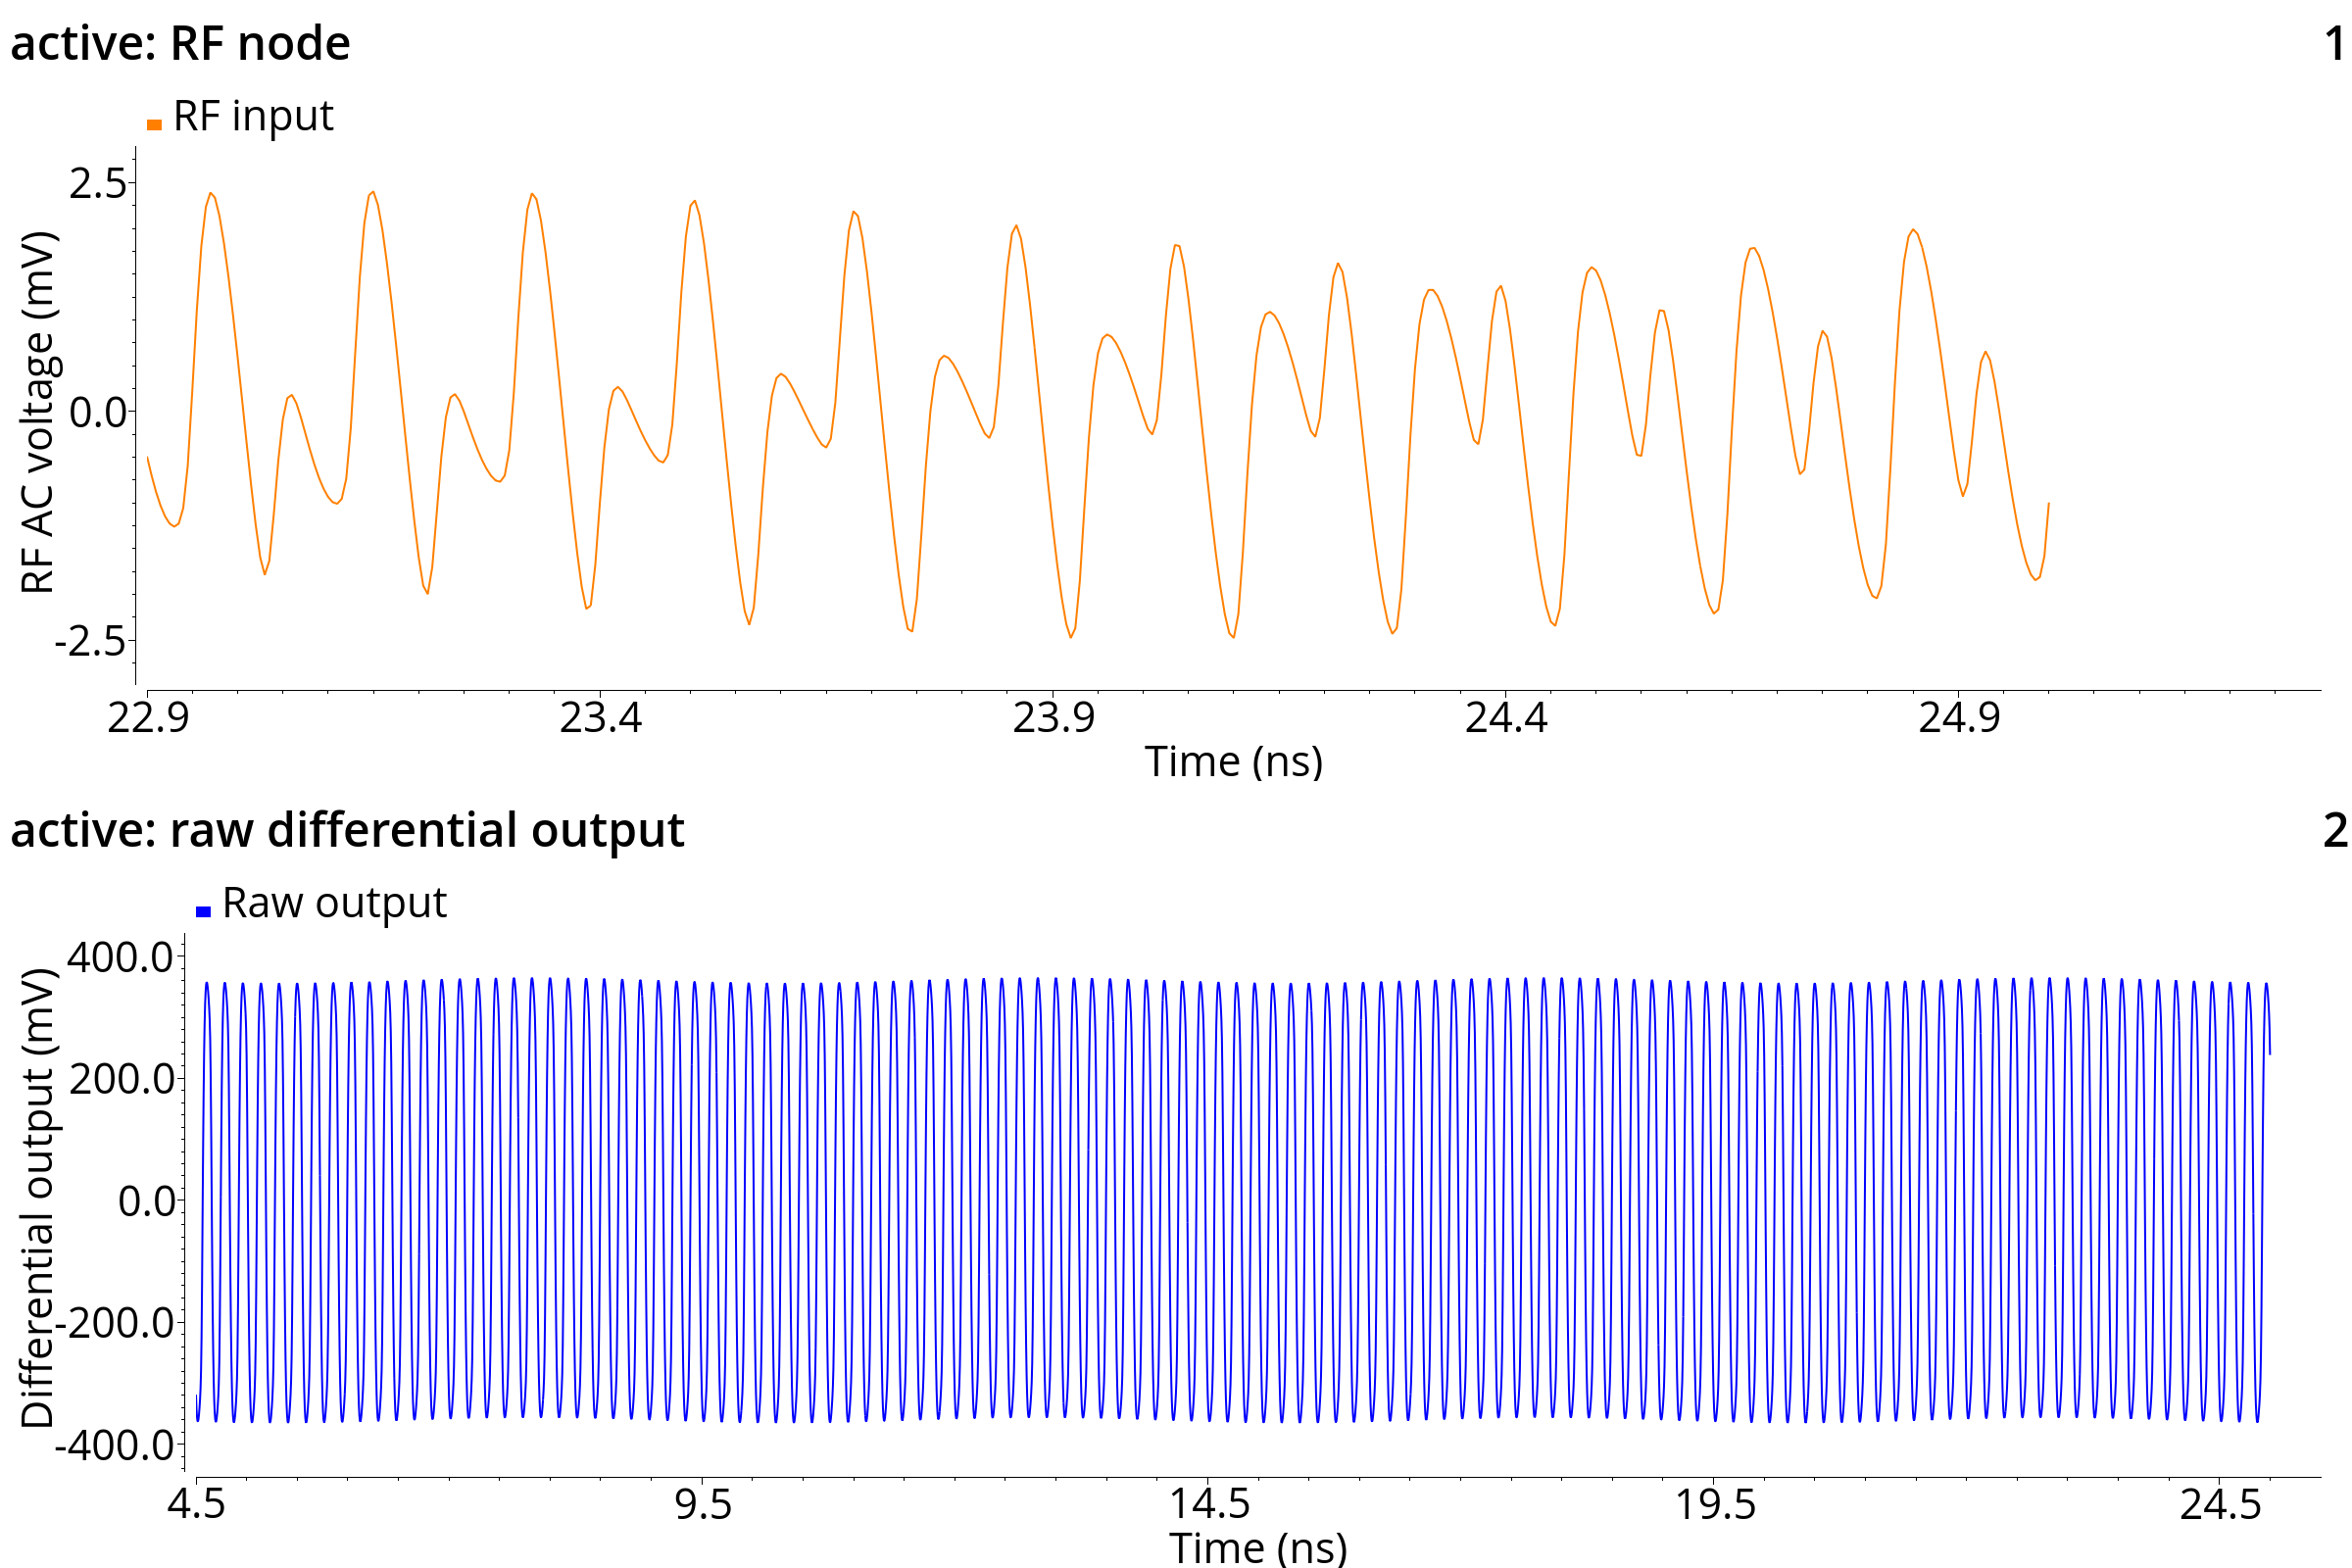

active_twotone_spectrum: actual native GUI export


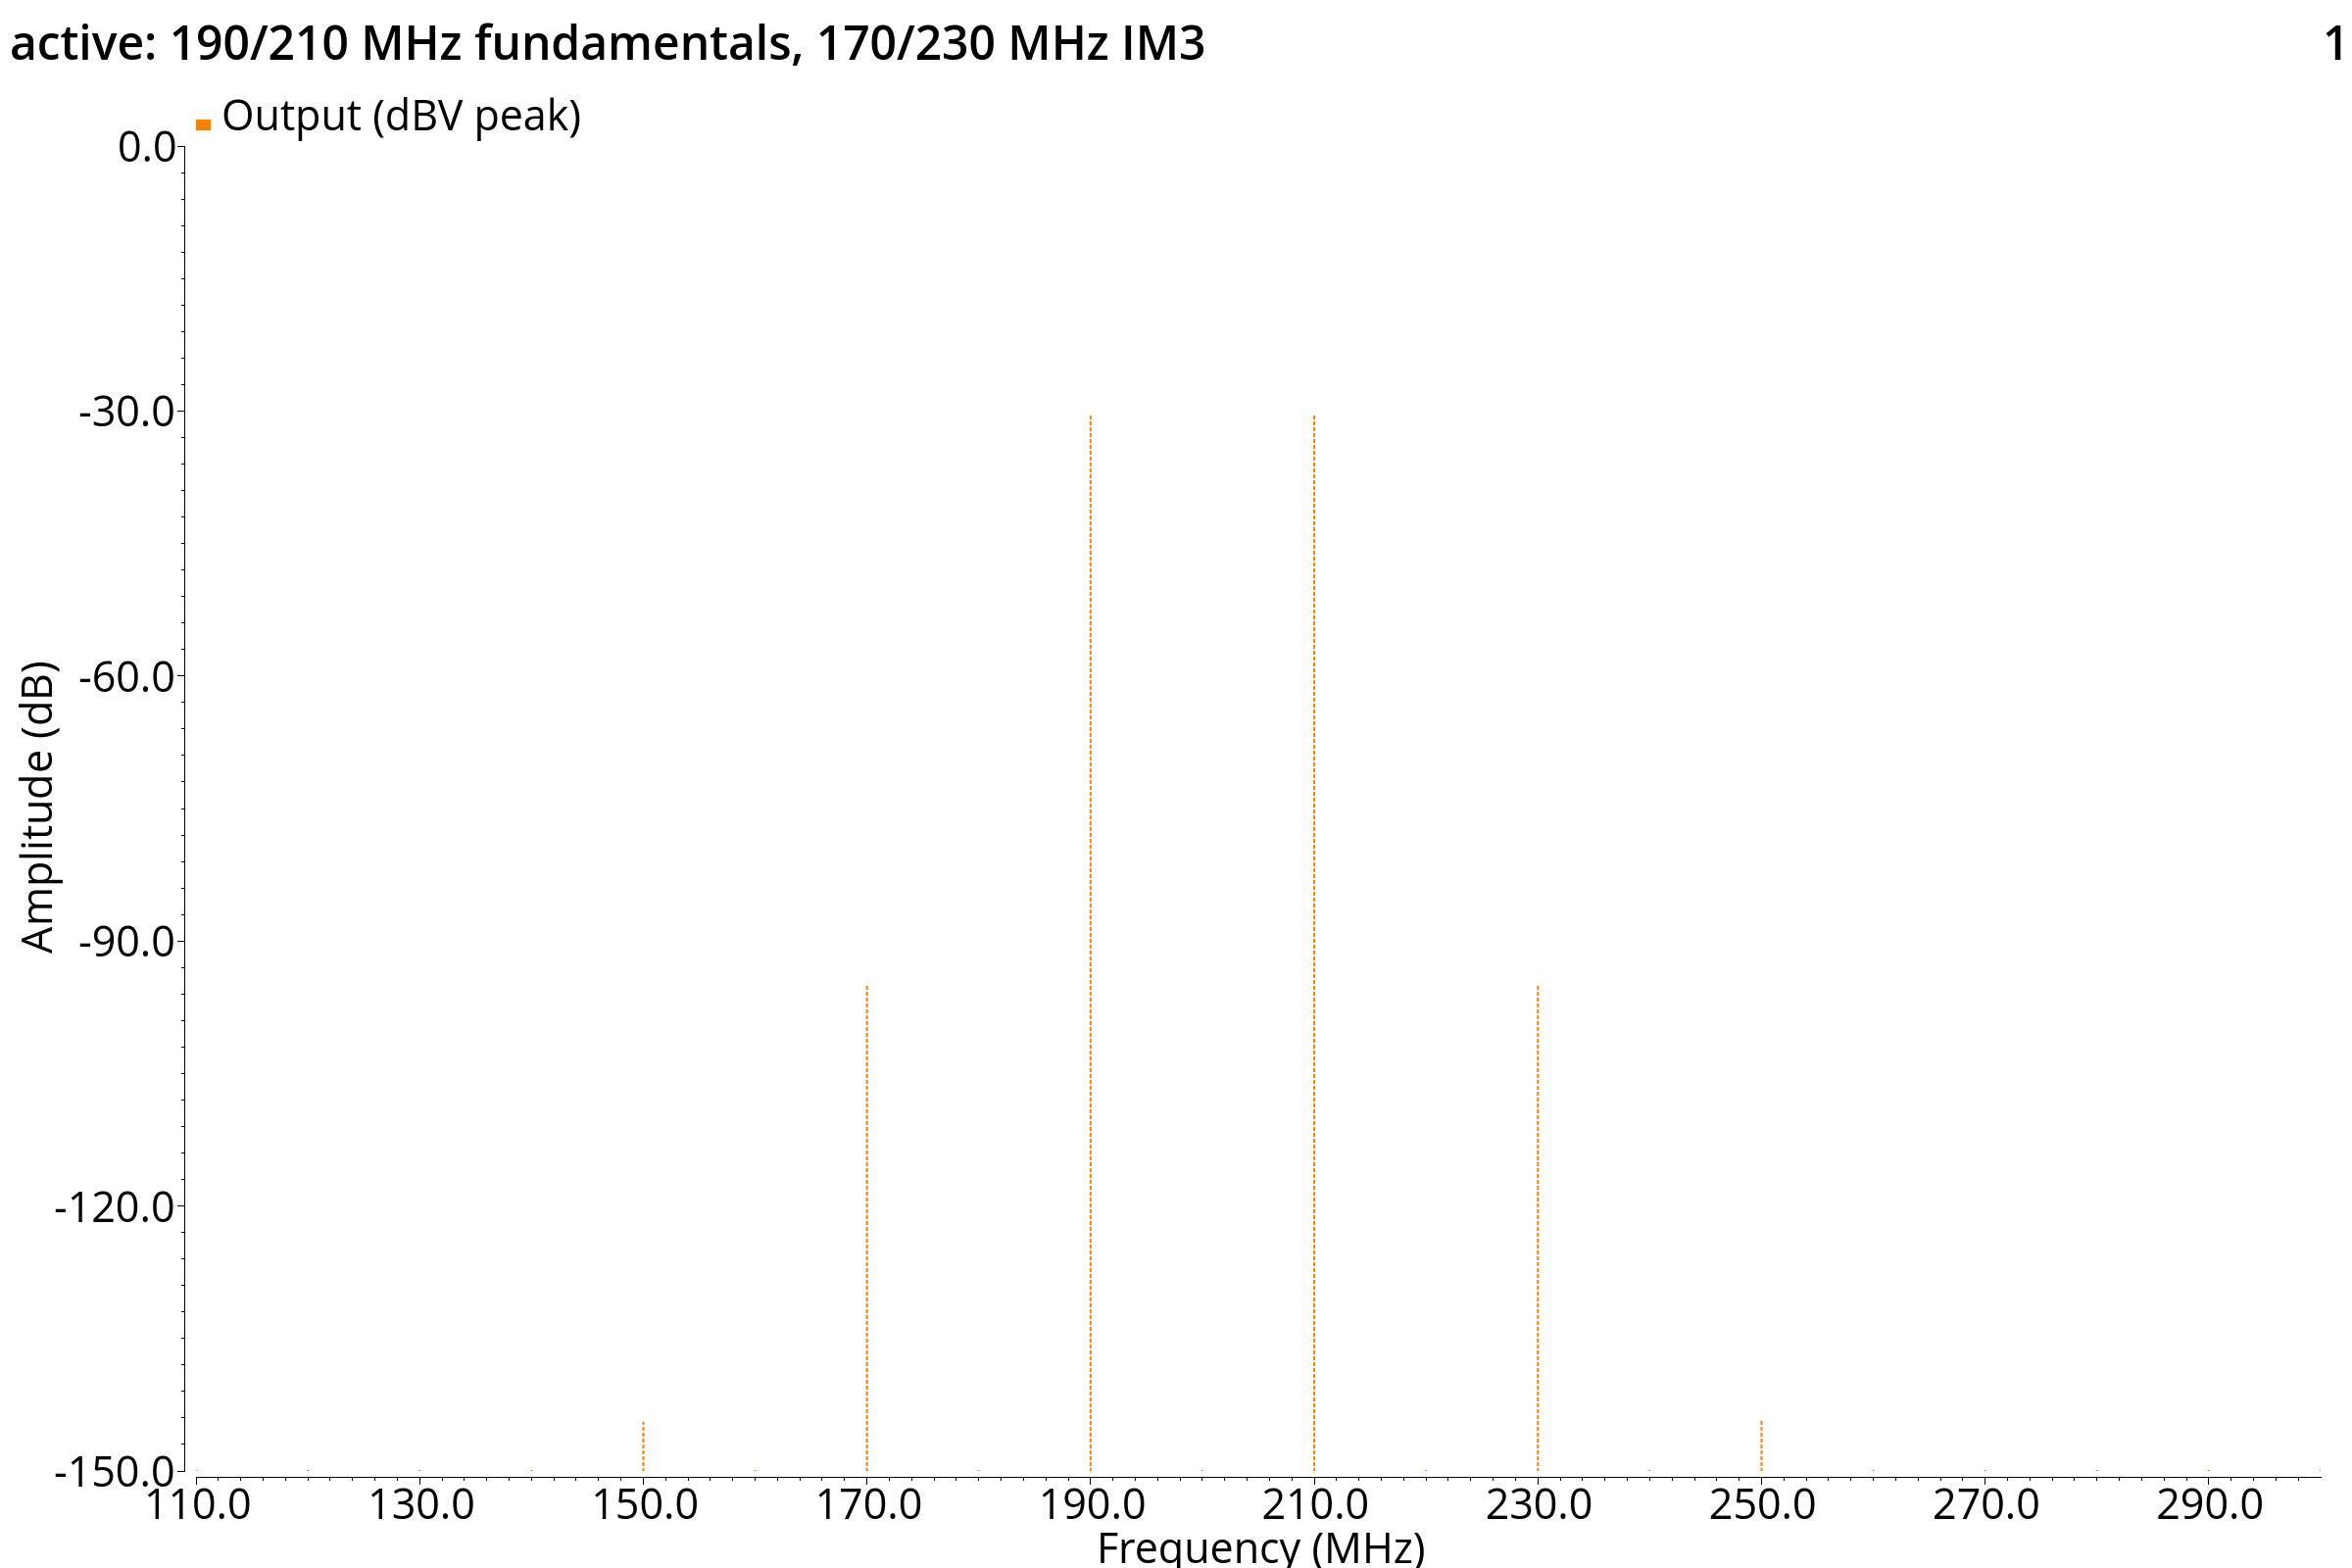

passive_compression: actual native GUI export


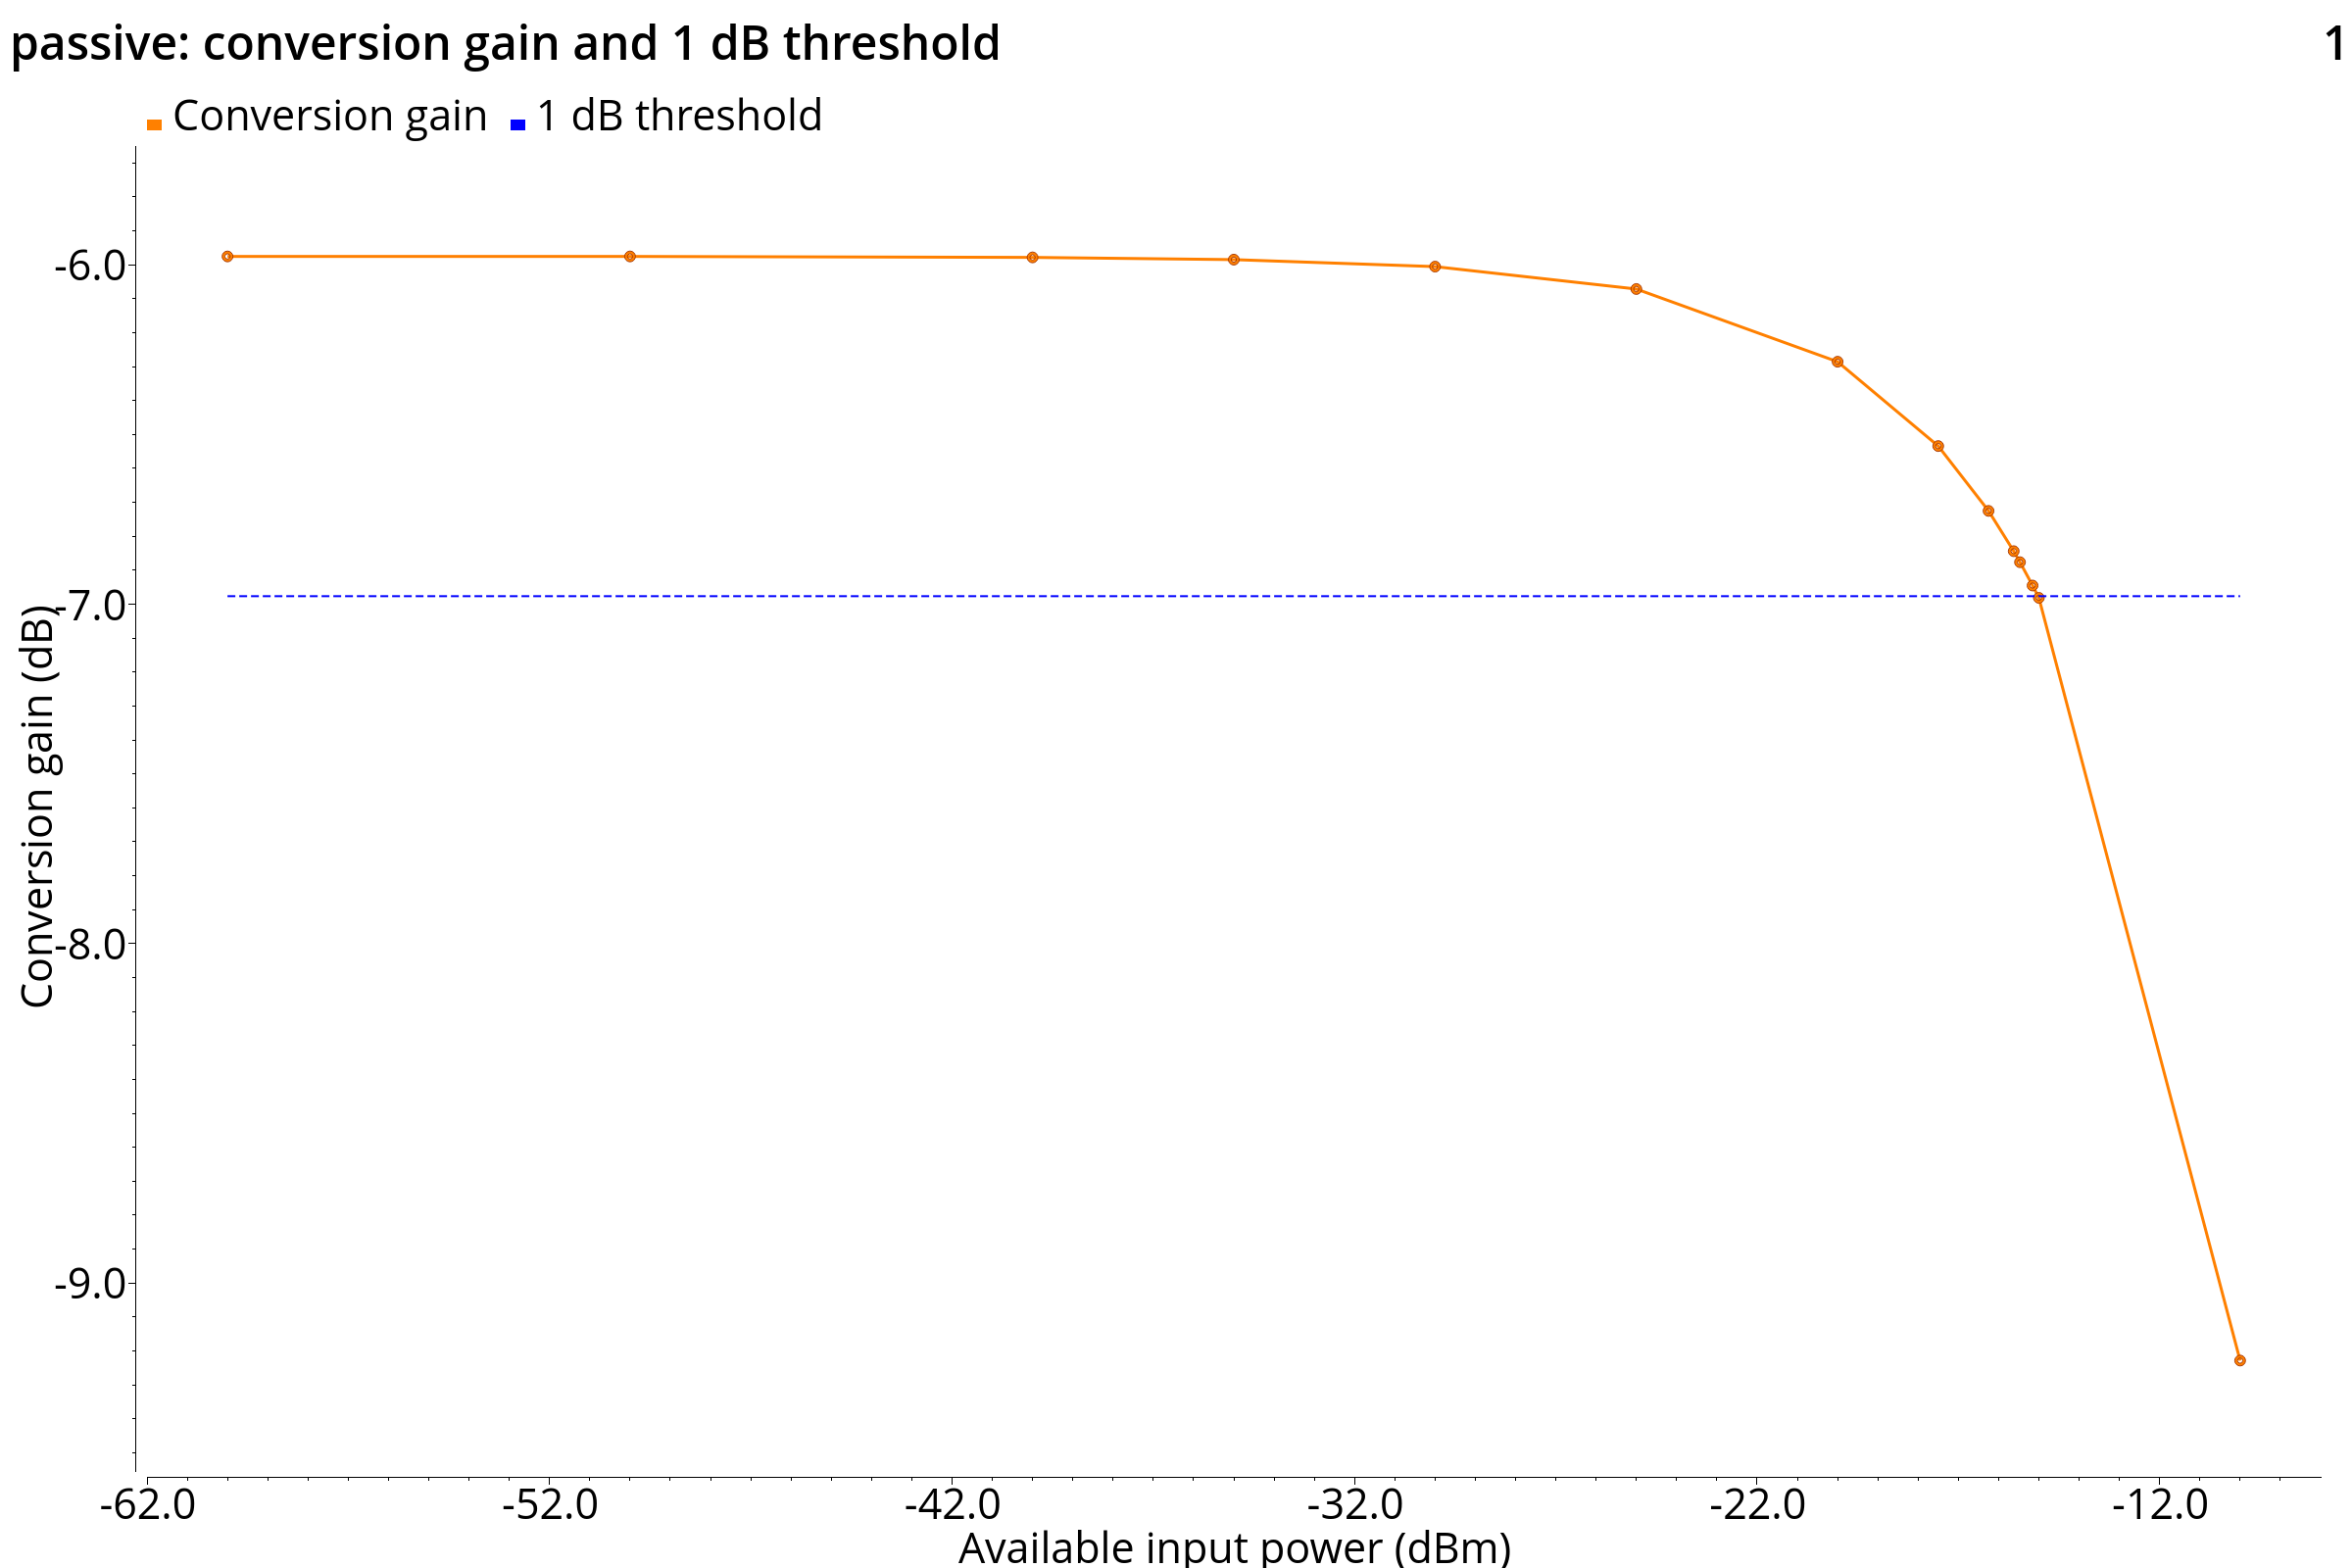

passive_iip3: actual native GUI export


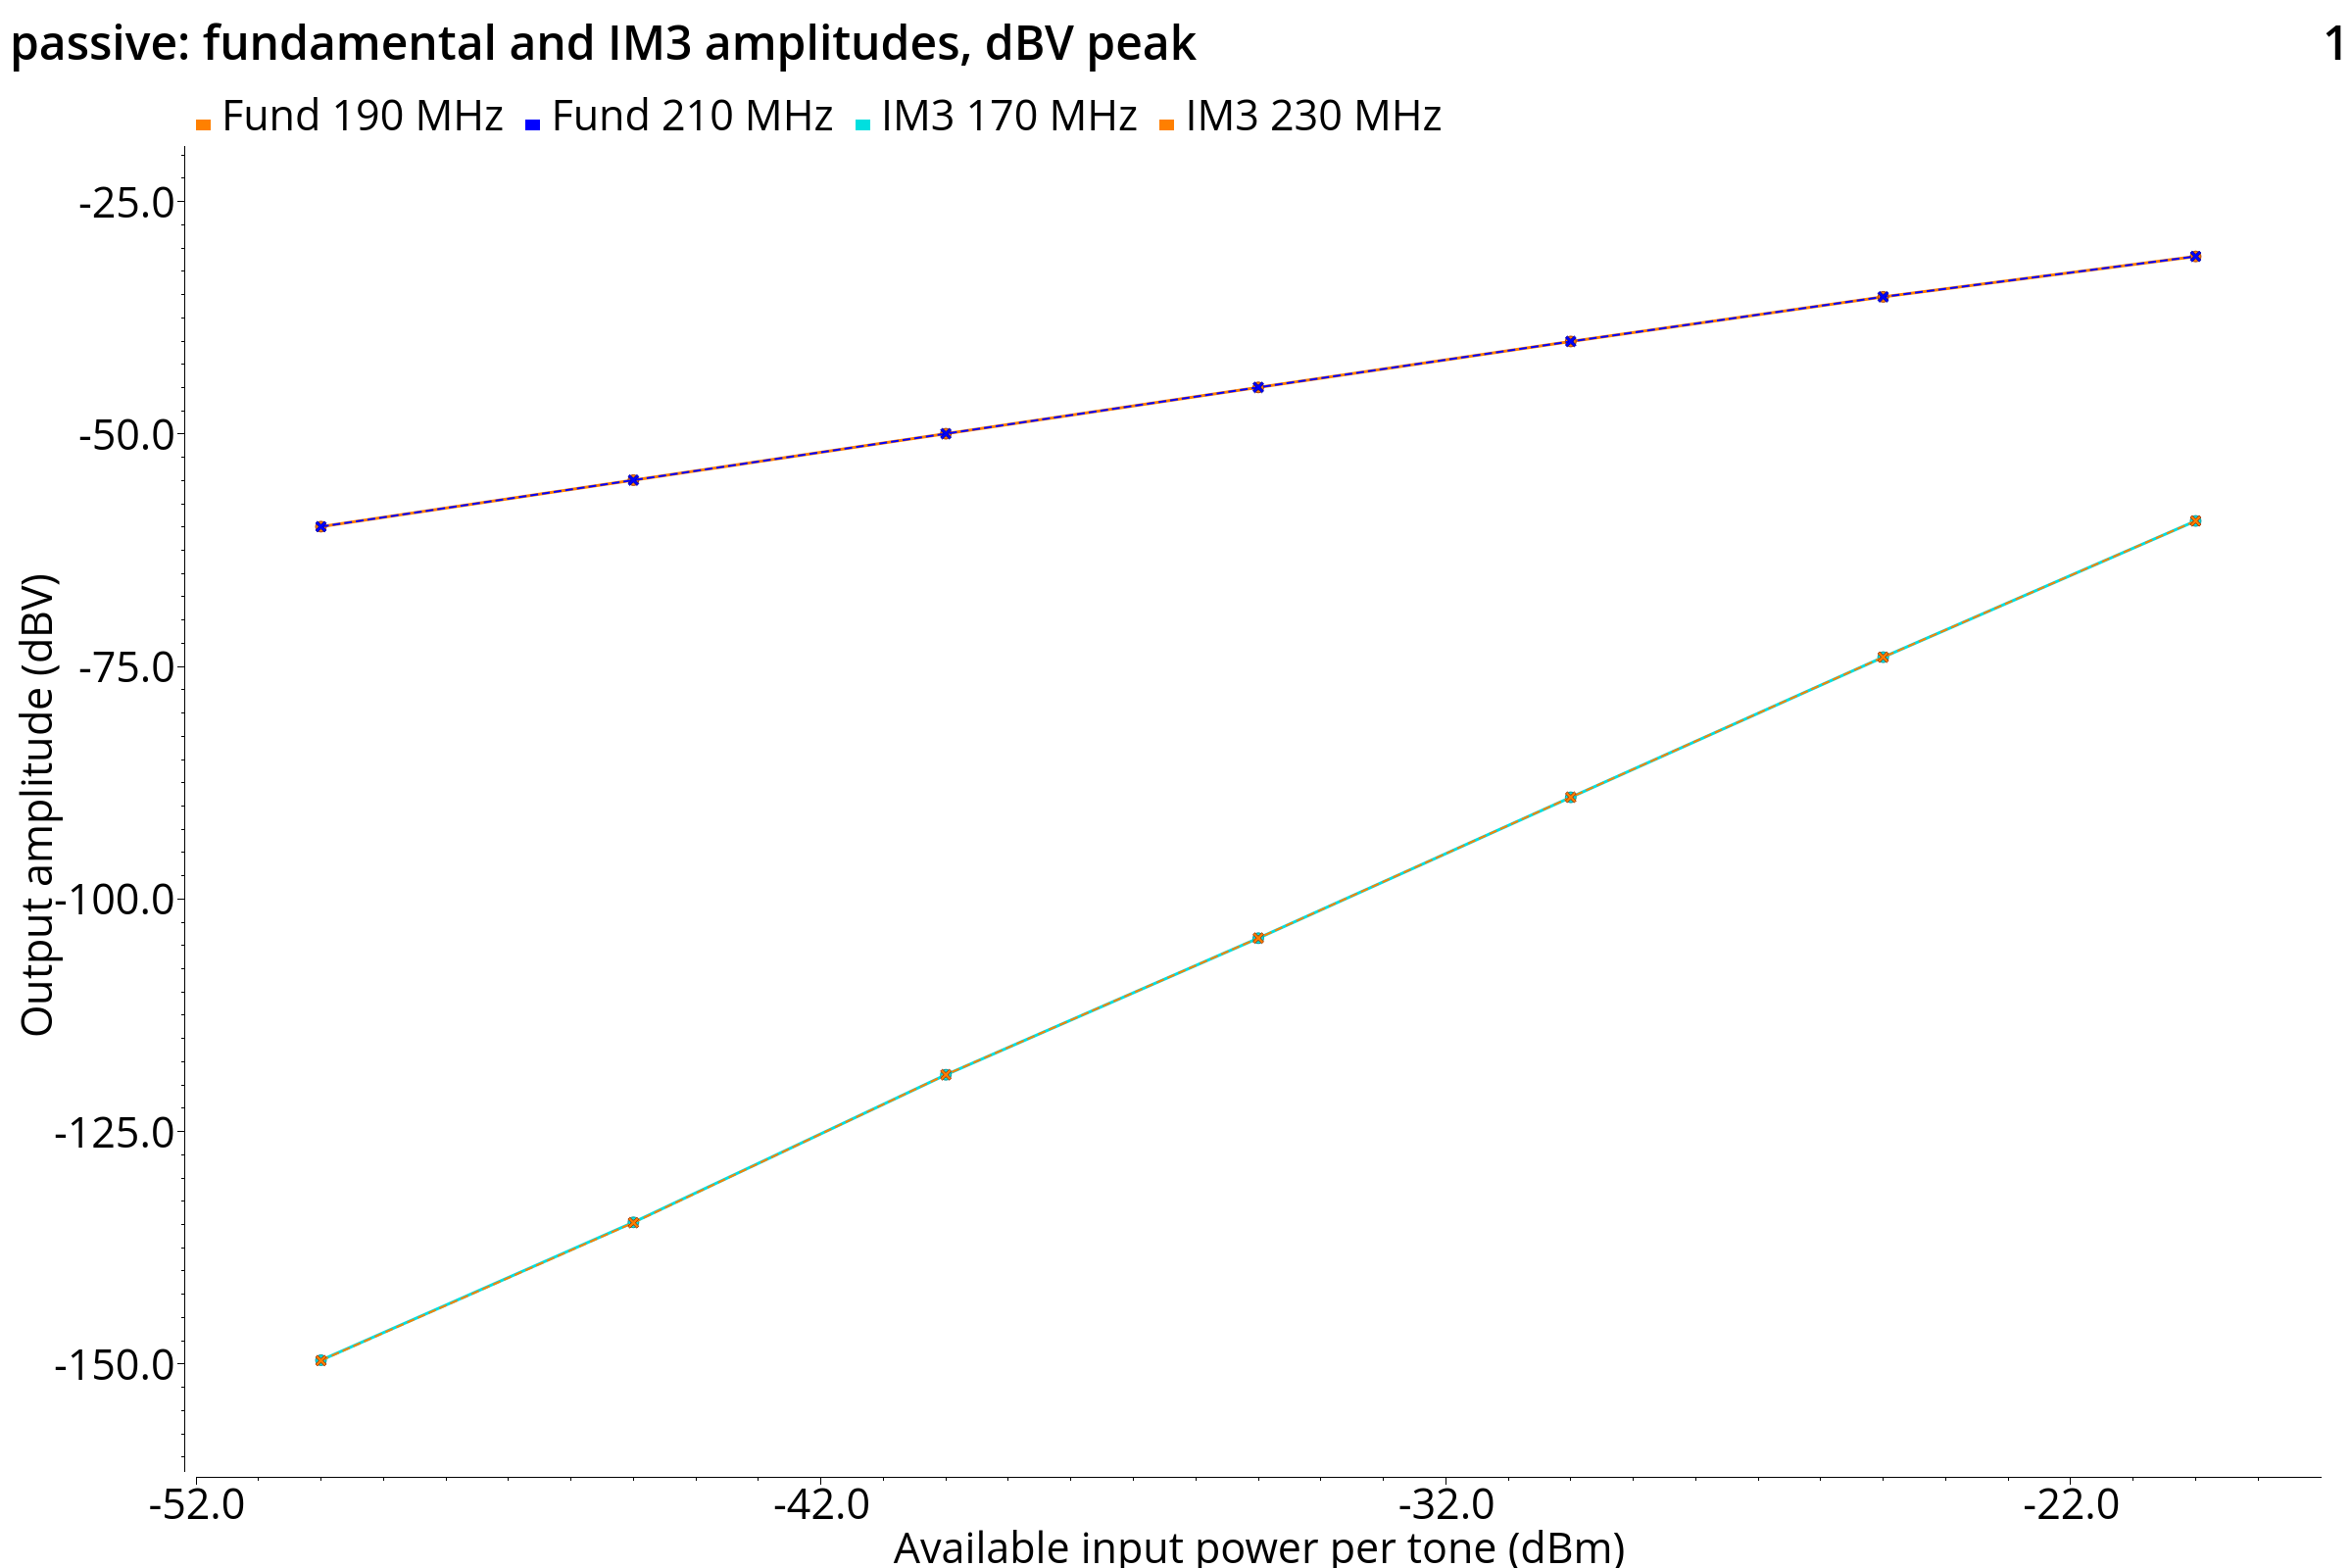

passive_noise: actual native GUI export


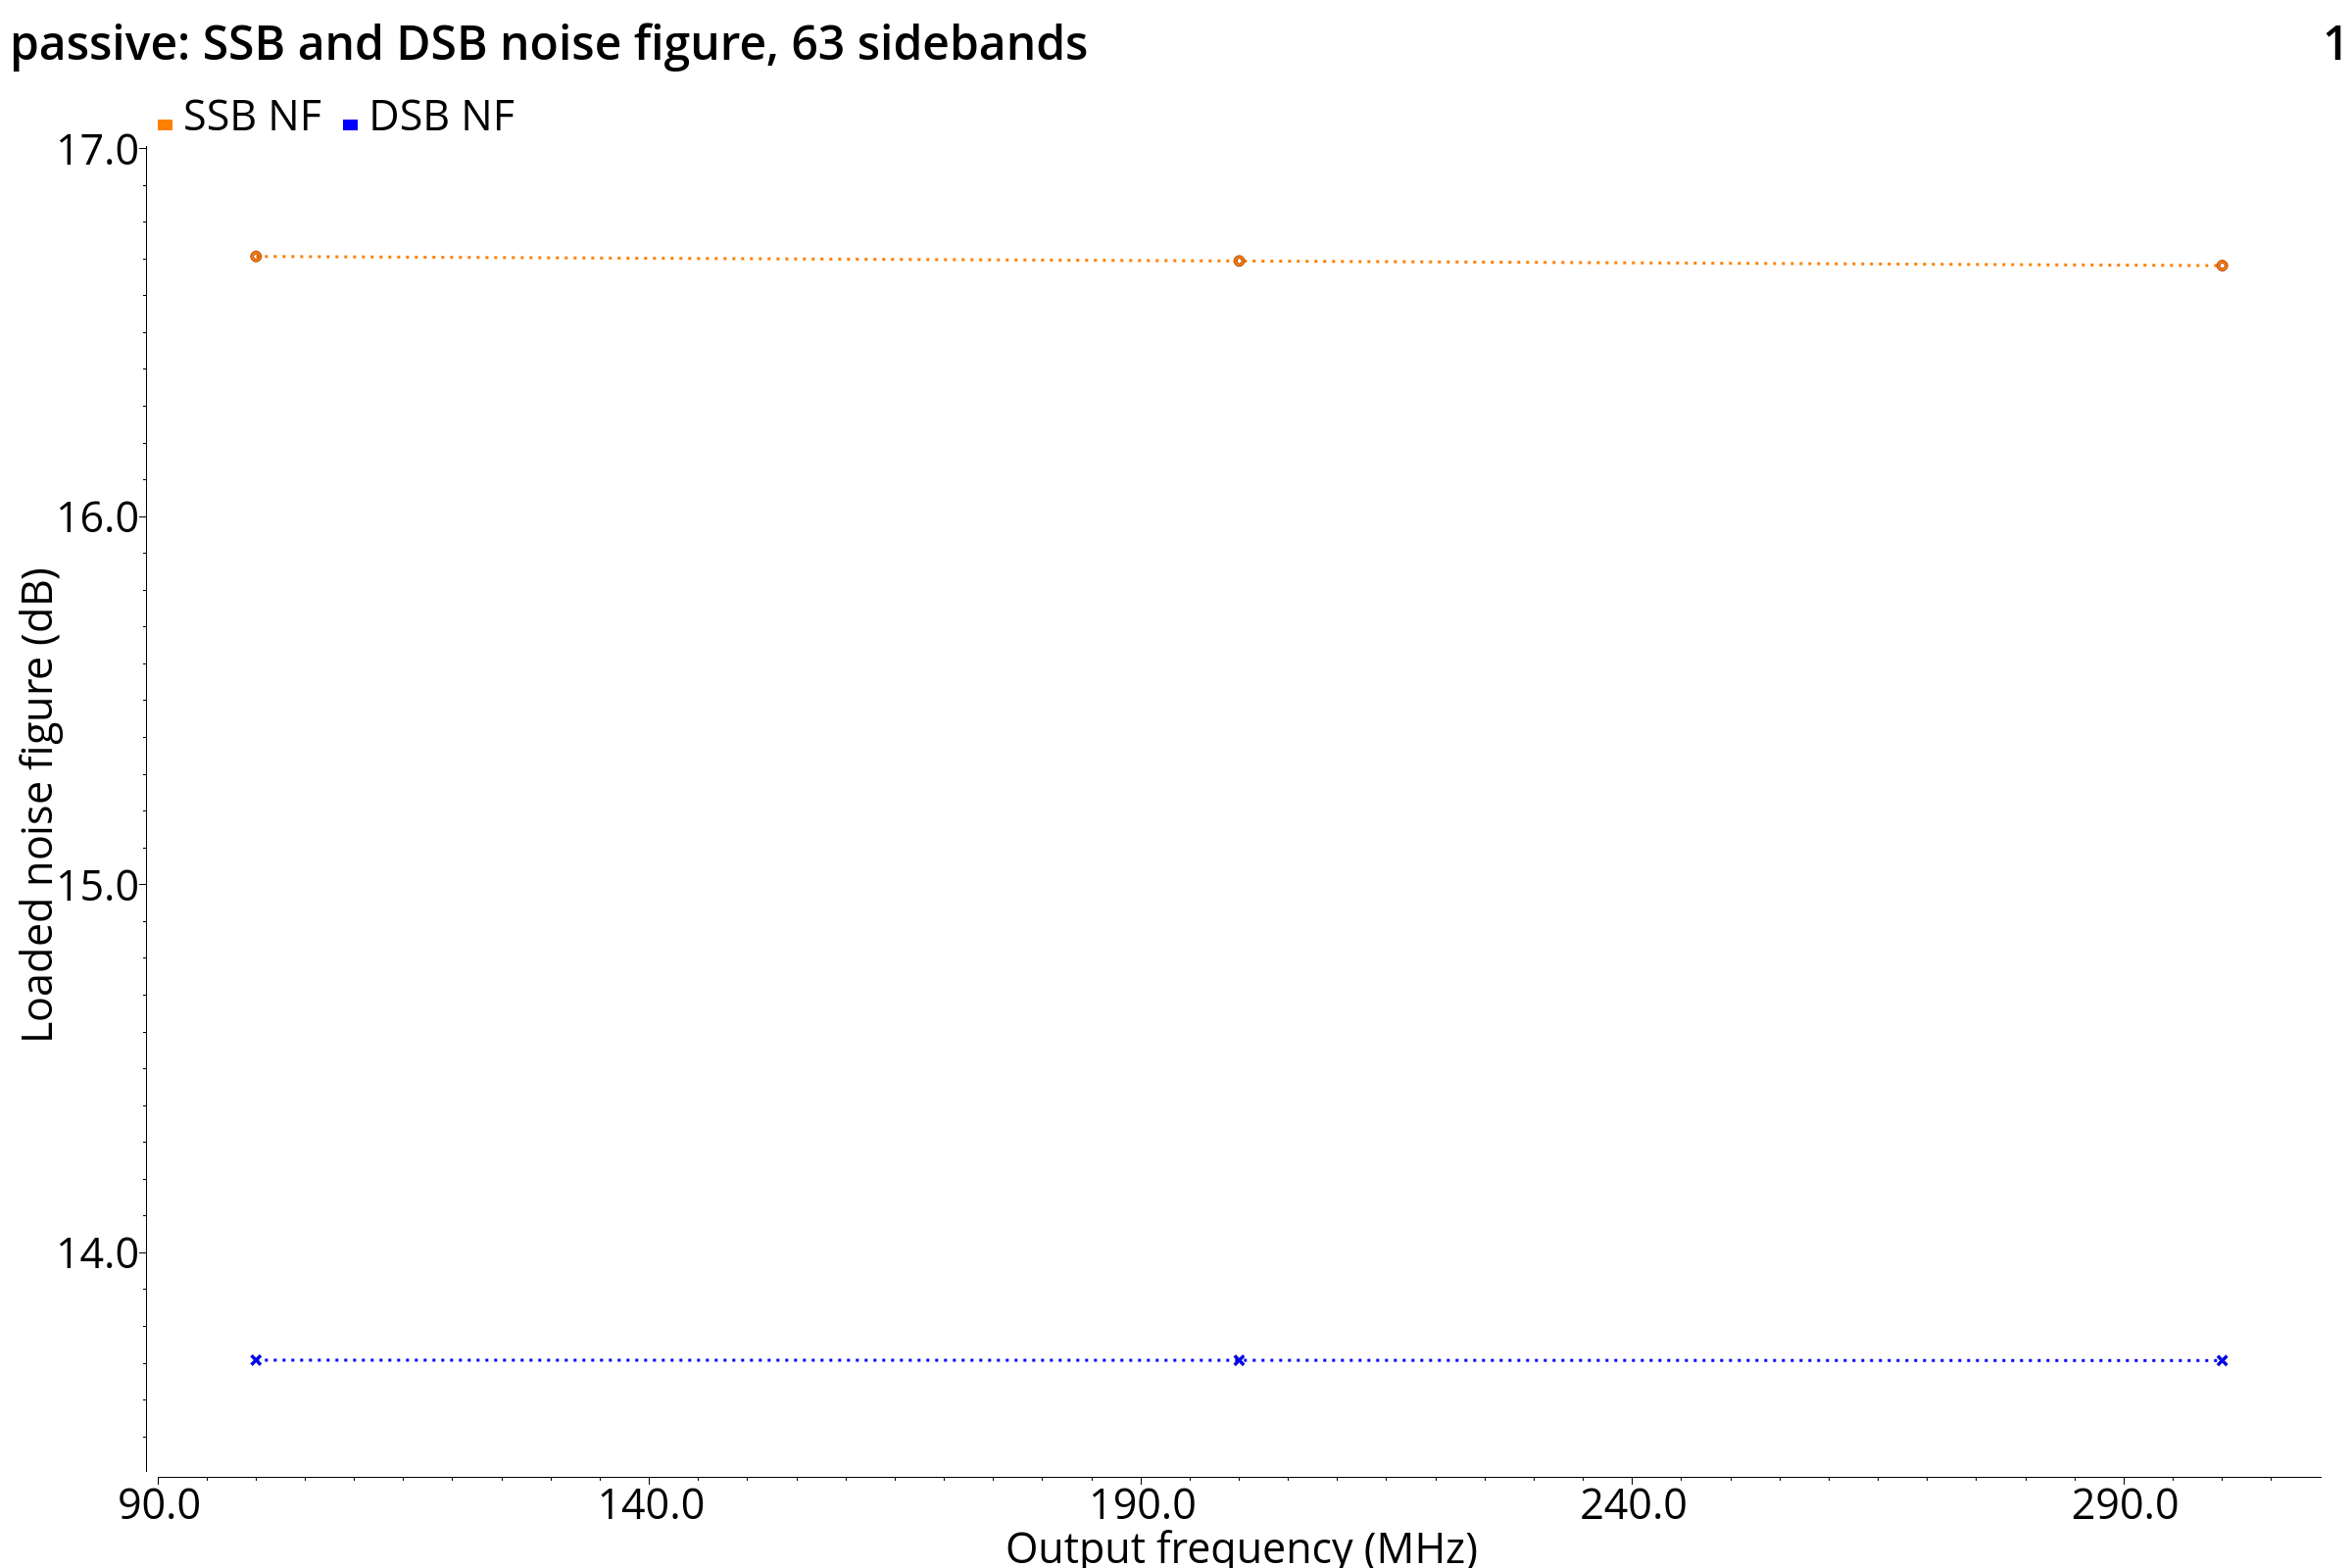

passive_spectrum: actual native GUI export


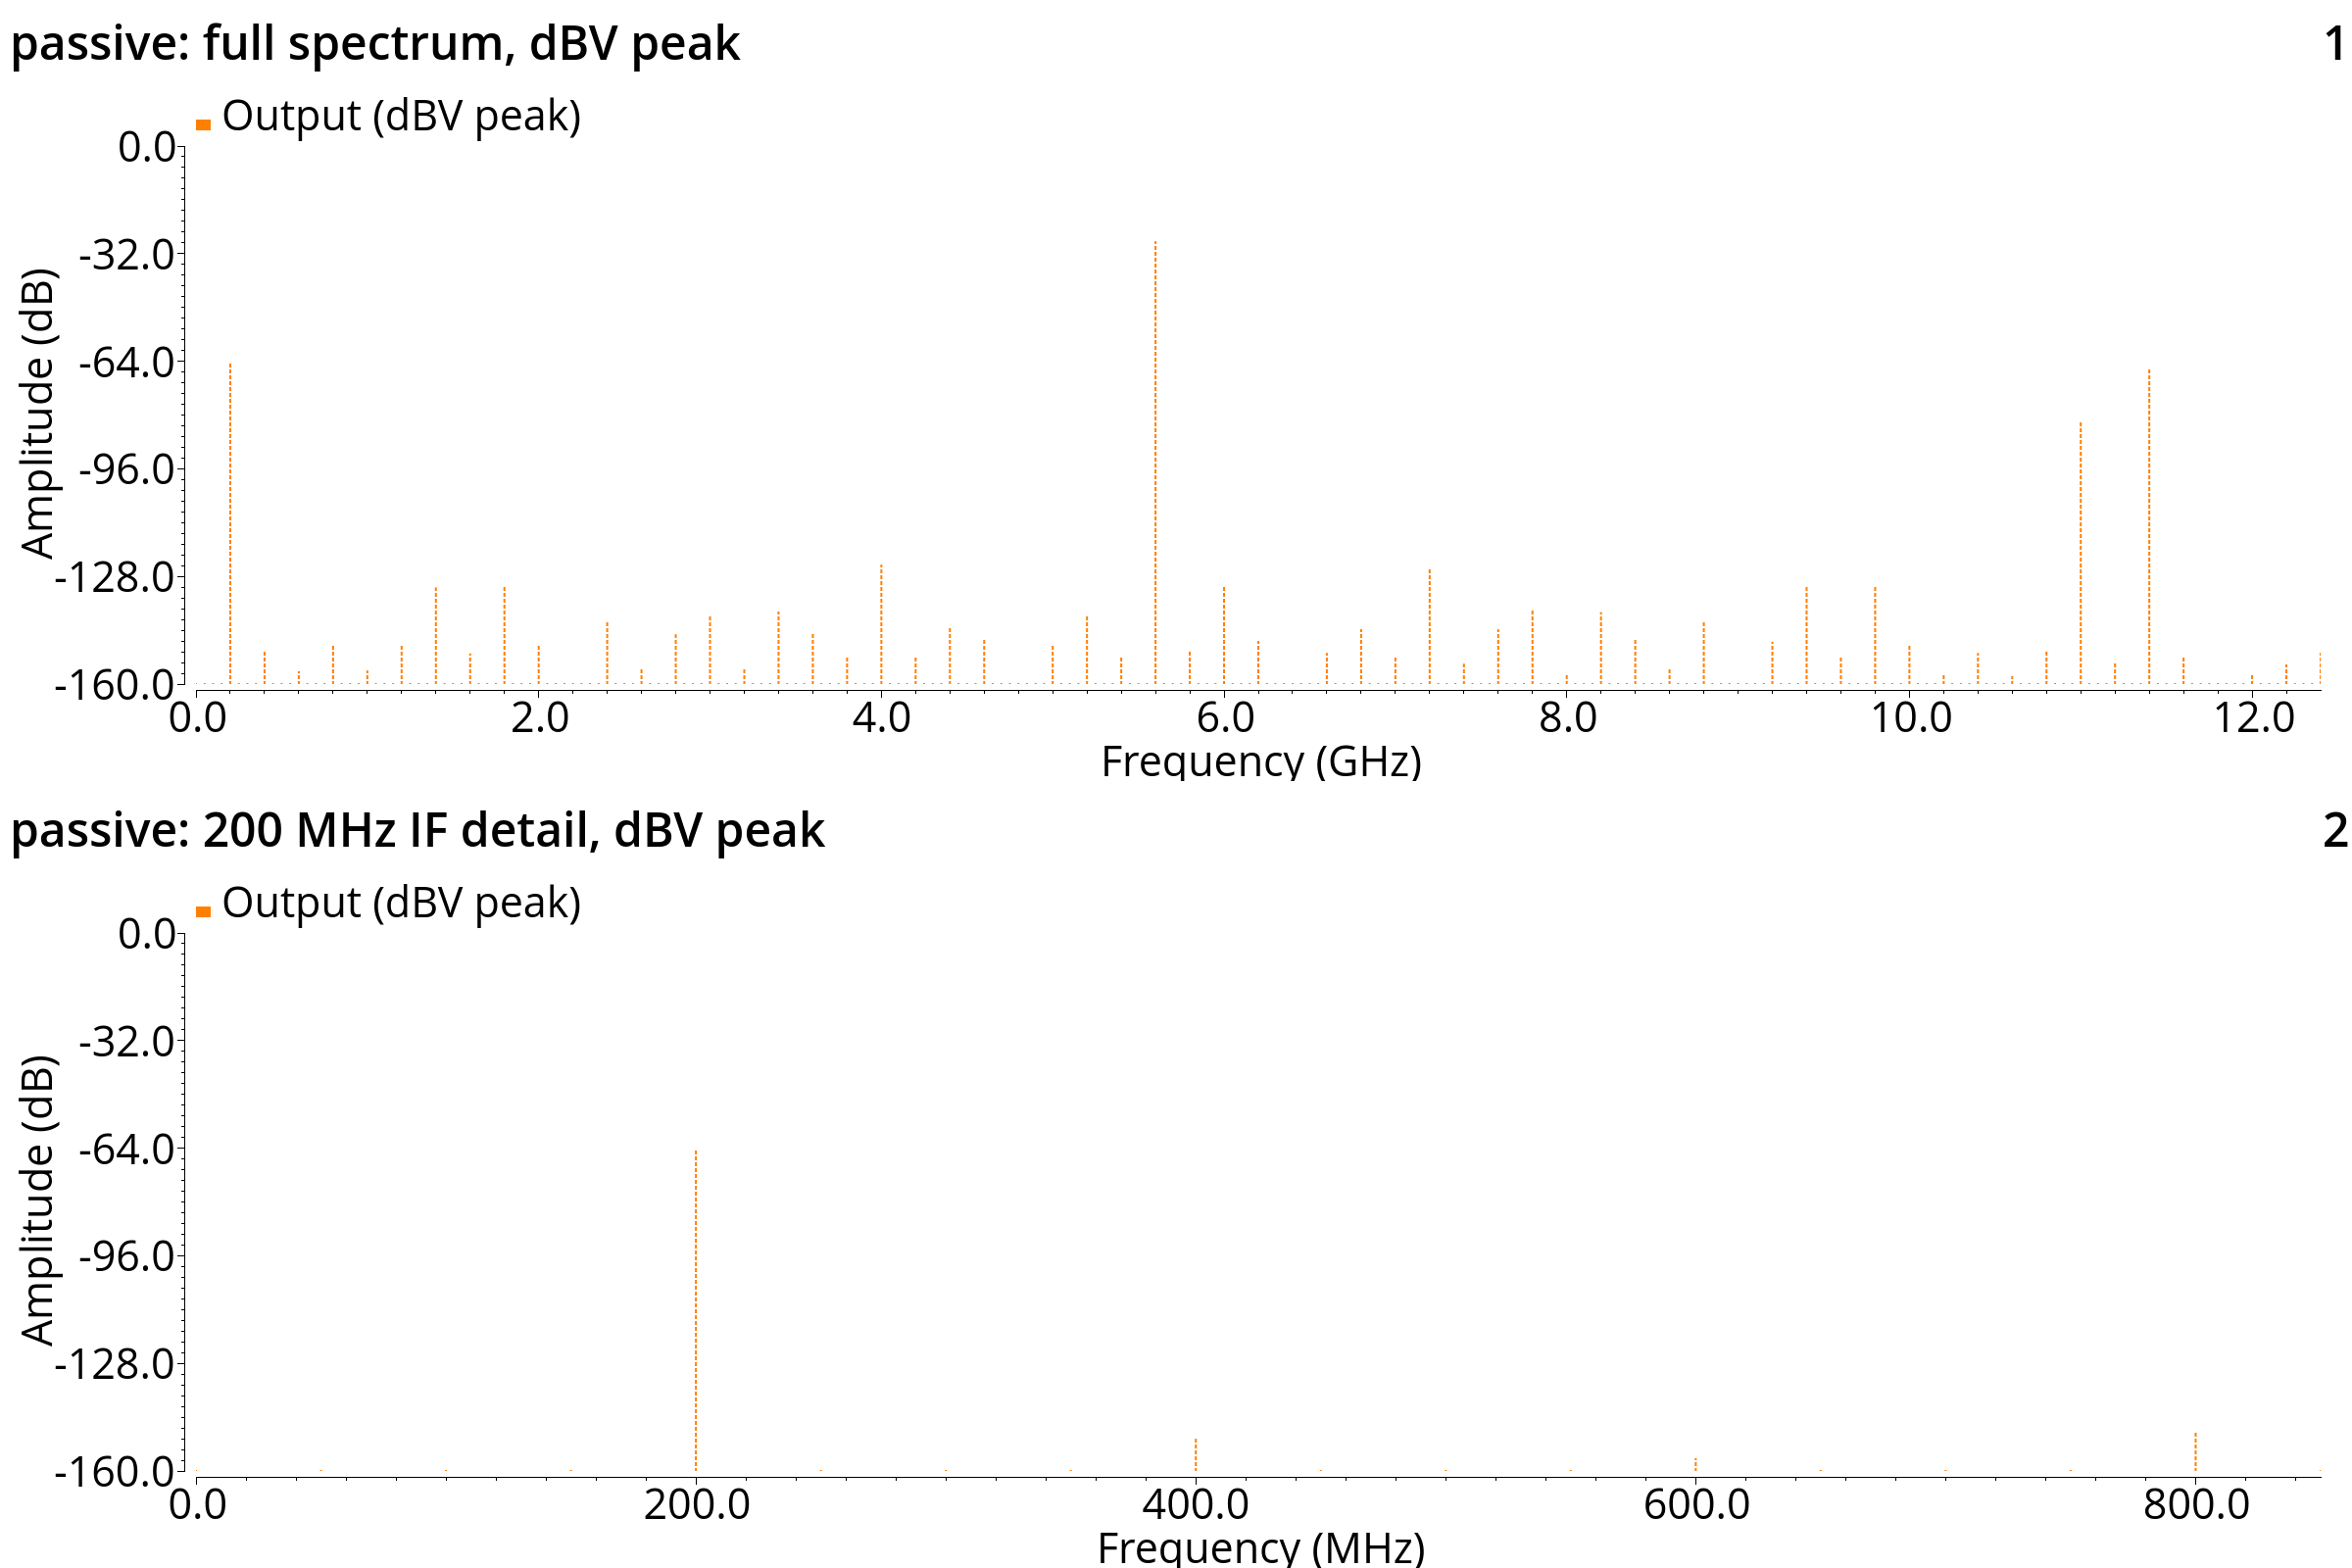

passive_transient: actual native GUI export


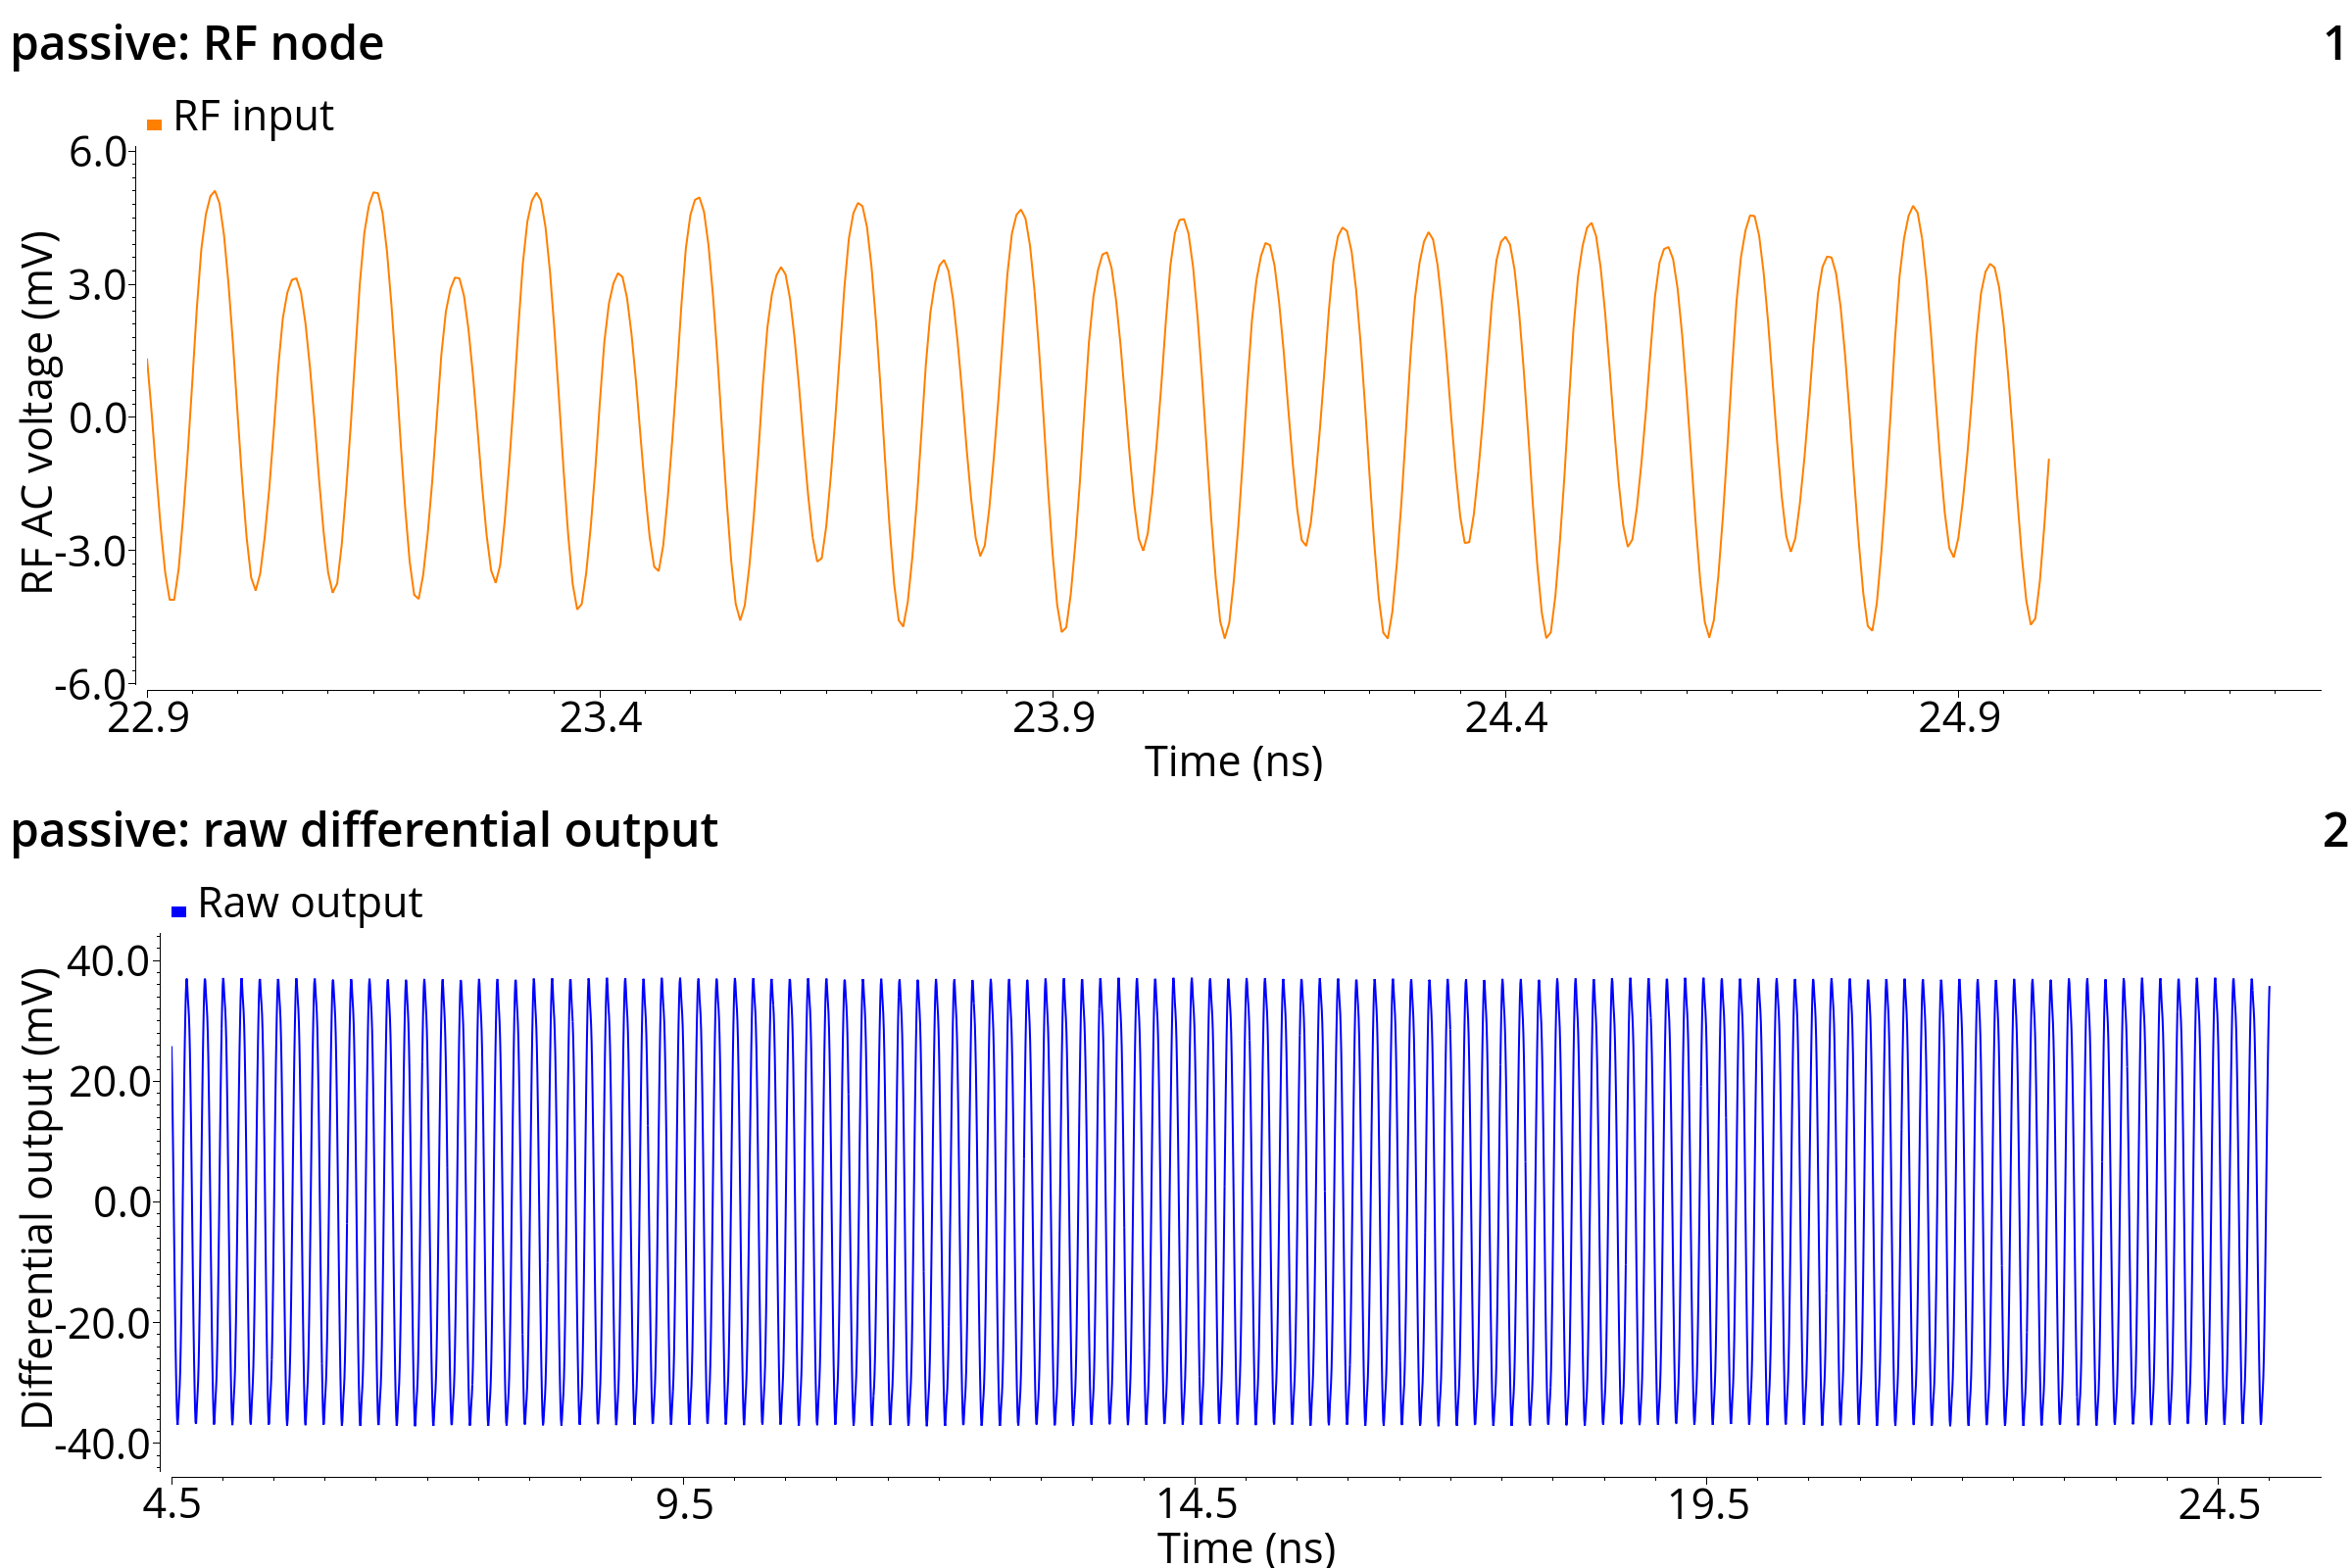

passive_twotone_spectrum: actual native GUI export


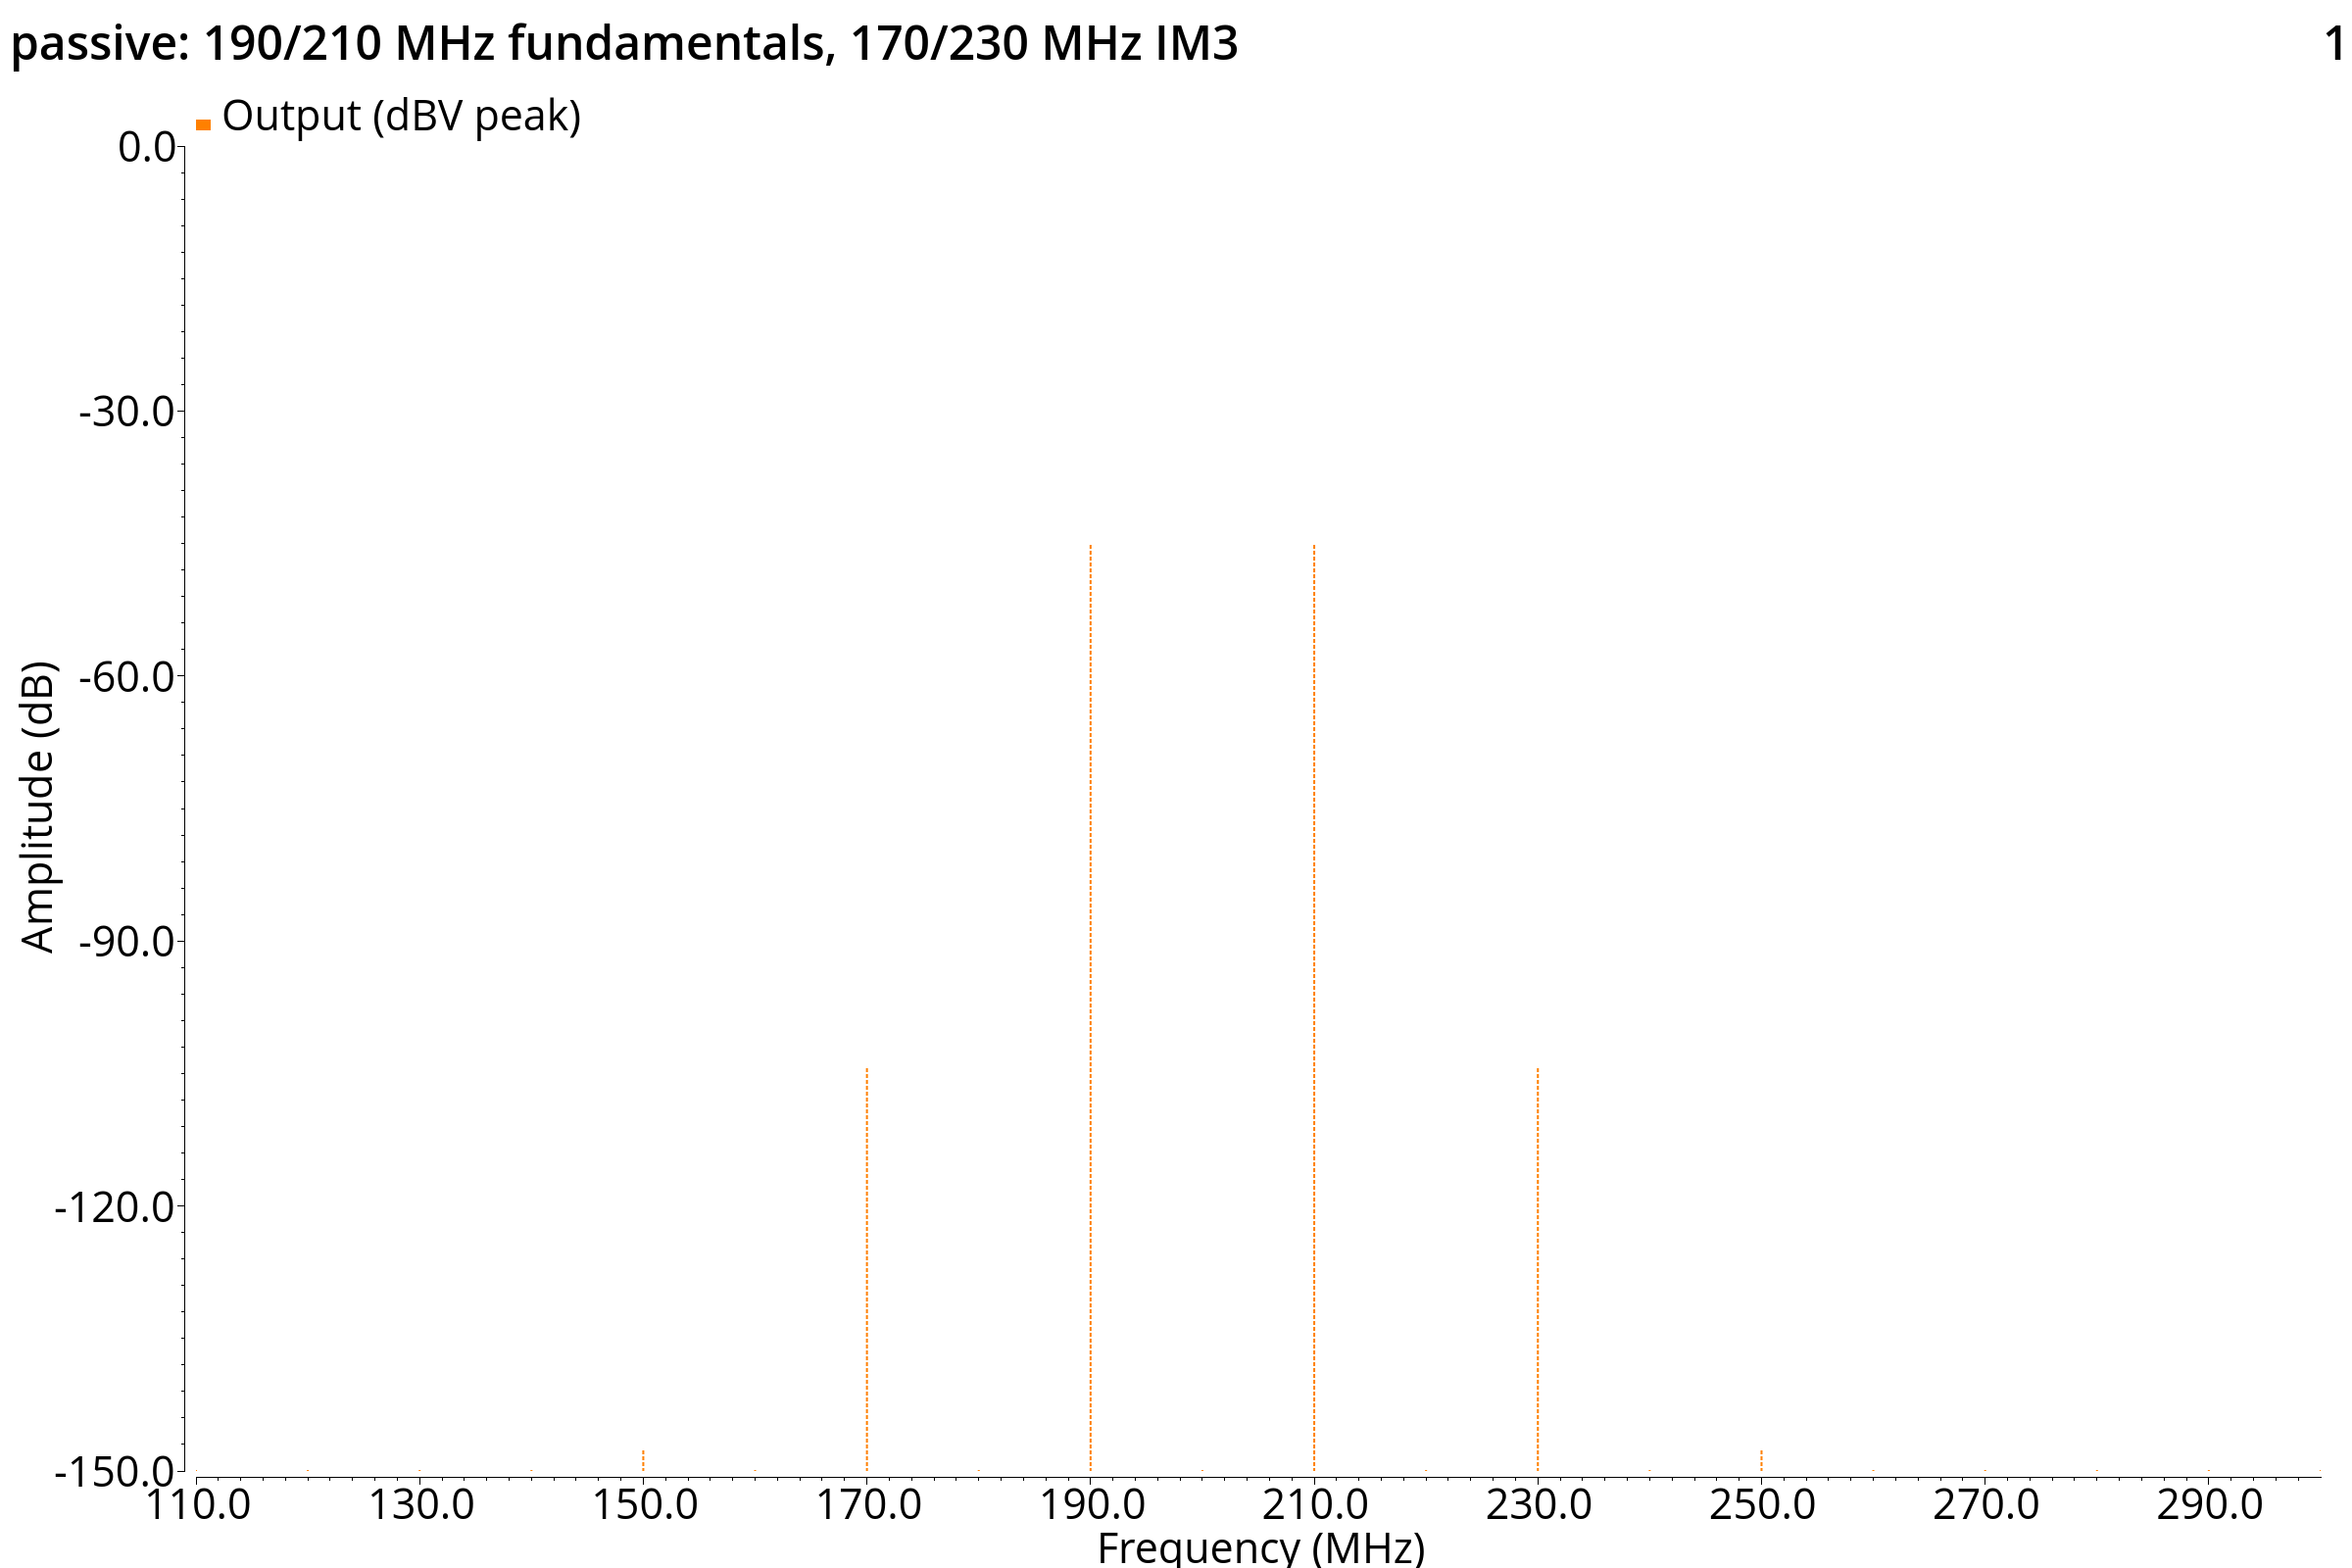

Verified review figures: 12


In [6]:
GUI_FIGURES = render_gui_figures(ROOT, show=True, allow_partial=ALLOW_PARTIAL_REVIEW)
print('Verified review figures:', len(GUI_FIGURES))

## Editable Overleaf source

The final step writes `overleaf/main.tex`, data-derived section includes, and local PNG figures from the complete actual GUI campaign. It does not compile a PDF or upload anything. Open `main.tex` in Overleaf and recompile there when desired. Editable `main.tex`, `macros.tex`, `references.bib`, and `sections/user_discussion.tex` are preserved on regeneration; generated sections and figures are refreshed. Missing or stale measurements are rejected.

In [7]:
if BUILD_TEX:
    if GUI_RESULTS['status'] != 'complete':
        raise RuntimeError('Complete actual GUI measurements are required before generating the LaTeX source.')
    source = render_gui_tex(ROOT)
    from IPython.display import FileLink, display
    display(FileLink(str(source)))
    print('Editable source and local PNG figures prepared. No PDF compiled or files uploaded.')
else:
    print('LaTeX generation skipped by BUILD_TEX=False.')

LaTeX generation skipped by BUILD_TEX=False.
